## 1. Data and plotting settings

In [1]:
from functools import partial
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator, FormatStrFormatter, MaxNLocator
from scipy.spatial import Delaunay

DATA_DIR = Path.cwd()
FIGURE4_OUTPUT_DIR = Path("figure4_revised")

# These selections affect the descriptive figures.
EXPERIMENTAL_REGIONS = [3]
STRETCH_PATH_REGIONS = [3]
SINGLE_SAMPLE_FITS = [(2, "C")]
REGIONAL_OVERLAYS = [1, 2, 3, 4, 5, 6]
PLOT_EXCLUSIONS_BY_REGION = {}   # Example: {3: ["1_0.75"]}
PLOT_EXCLUSIONS_BY_SAMPLE = {}   # Example: {(3, "C"): ["1_0.75"]}
PLOT_POINT_STEP = 3
SINGLE_SAMPLE_STRESS_WINDOW = "experimental"  # Or "combined".

SAMPLES = ("A", "B", "C")
REGION_NAMES = {
    1: "Neck", 2: "RF Axilla", 3: "LF Axilla", 4: "LH Inguinal",
    5: "LF Shoulder Lateral", 6: "RH Inguinal",
}
PROTOCOL_FILES = {
    "1_1_end": "4Dots_Stretch_1PK_1_1end.txt",
    "1_0.75": "4Dots_Stretch_1PK_1_075.txt",
    "1_0.5": "4Dots_Stretch_1PK_1_05.txt",
    "0.75_1": "4Dots_Stretch_1PK_075_1.txt",
    "0.5_1": "4Dots_Stretch_1PK_05_1.txt",
}
PROTOCOL_LABELS = {
    "1_1_end": "1:1", "1_0.75": "1:0.75", "1_0.5": "1:0.5",
    "0.75_1": "0.75:1", "0.5_1": "0.5:1",
}
PROTOCOL_MARKERS = {
    "1_1_end": "o", "1_0.75": "^", "1_0.5": "s",
    "0.75_1": "D", "0.5_1": "v",
}
SAMPLE_COLORS = {"A": "red", "B": "green", "C": "blue"}
CAMERA_VIEWS = (("Perspective", 22, -130), ("Side", 22, -32))

STRETCH_COLUMNS = ["lambda11", "lambda22"]
STRESS_COLUMNS = ["sigma11", "sigma22"]
POINTS_PER_PROTOCOL = 300

In [2]:
def load_experimental_data(data_dir):
    data_dir = Path(data_dir).expanduser().resolve()
    sample_folders = sorted(path for path in data_dir.glob("[0-9][0-9]_*") if path.is_dir())
    expected_count = len(REGION_NAMES) * len(SAMPLES)
    if len(sample_folders) != expected_count:
        raise FileNotFoundError(
            f"Expected {expected_count} numbered sample folders in {data_dir}, "
            f"found {len(sample_folders)}. Set DATA_DIR to the folder containing the specimens."
        )

    measurements = []
    for index, folder in enumerate(sample_folders):
        region_index, sample_index = divmod(index, len(SAMPLES))
        if not folder.name.endswith(f"Sample{sample_index + 1}"):
            raise ValueError(f"Unexpected sample order at {folder}. Expected Sample{sample_index + 1}.")

        for protocol, filename in PROTOCOL_FILES.items():
            path = folder / "all" / filename
            if not path.is_file():
                raise FileNotFoundError(f"Missing protocol file {path}")

            columns = ["Time", *STRETCH_COLUMNS, "P11", "P22"]
            data = pd.read_csv(path, comment="#", header=None)
            expected_shape = (POINTS_PER_PROTOCOL, len(columns))
            if data.shape != expected_shape:
                raise ValueError(f"{path}: expected {expected_shape} rows and columns, got {data.shape}.")
            data.columns = columns
            try:
                data = data.astype(float)
            except ValueError as error:
                raise ValueError(f"{path}: expected numeric measurements.") from error
            if not np.isfinite(data.to_numpy()).all():
                raise ValueError(f"{path}: measurements must be finite.")
            if (data[STRETCH_COLUMNS] <= 0).any().any():
                raise ValueError(f"{path}: stretches must be positive.")

            data["region_id"] = region_index + 1
            data["sample"] = SAMPLES[sample_index]
            data["protocol"] = protocol
            data["point_index"] = np.arange(len(data))
            measurements.append(data)

    combined = pd.concat(measurements, ignore_index=True)
    combined["sigma11"] = combined["P11"] * combined["lambda11"]
    combined["sigma22"] = combined["P22"] * combined["lambda22"]
    if not np.isfinite(combined[STRESS_COLUMNS].to_numpy()).all():
        raise ValueError("Cauchy stress conversion produced non-finite values.")
    return combined


combined_df = load_experimental_data(DATA_DIR)
sample_count = combined_df.groupby(["region_id", "sample"]).ngroups
protocol_count = combined_df.groupby(["region_id", "sample", "protocol"]).ngroups
print(f"Loaded {len(combined_df):,} states from {sample_count} samples and {protocol_count} protocol files.")

Loaded 27,000 states from 18 samples and 90 protocol files.


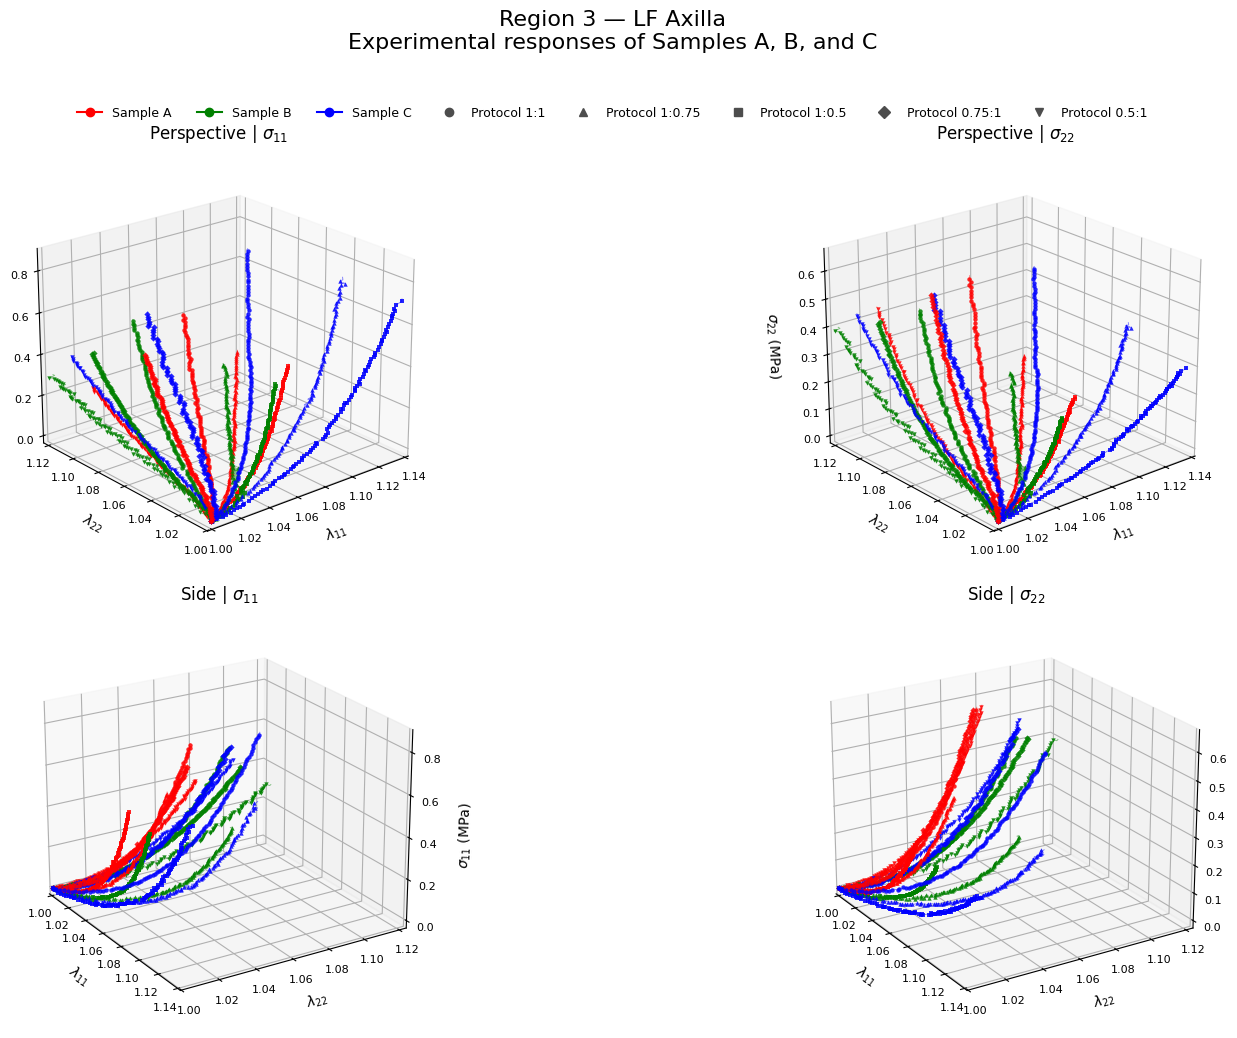

In [3]:
def get_plot_measurements(region_id, sample=None):
    region = combined_df.loc[combined_df["region_id"].eq(region_id)]
    if sample is not None:
        region = region.loc[region["sample"].eq(sample)]
    excluded = set(PLOT_EXCLUSIONS_BY_REGION.get(region_id, ()))
    if excluded.difference(PROTOCOL_FILES):
        raise ValueError(f"Unknown plot protocols in Region {region_id}: {sorted(excluded)}")
    region = region.loc[~region["protocol"].isin(excluded)]

    for (target_region, target_sample), protocols in PLOT_EXCLUSIONS_BY_SAMPLE.items():
        if target_region != region_id:
            continue
        if target_sample not in SAMPLES or set(protocols).difference(PROTOCOL_FILES):
            raise ValueError(f"Invalid plot exclusions for Region {region_id}, Sample {target_sample}.")
        drop = region["sample"].eq(target_sample) & region["protocol"].isin(protocols)
        region = region.loc[~drop]

    if region.empty:
        raise ValueError(f"No measurements selected for Region {region_id}, sample {sample or 'A/B/C'}.")
    return region



def plot_region_3d(region_id, point_step=3):
    if point_step < 1:
        raise ValueError("point_step must be at least 1.")
    region_df = get_plot_measurements(region_id)
    included_protocols = [
        p for p in PROTOCOL_FILES if region_df["protocol"].eq(p).any()
    ]
    included_samples = [
        s for s in SAMPLES if region_df["sample"].eq(s).any()
    ]

    # Use identical axis limits for perspective and side views.
    xlim = (region_df["lambda11"].min(), region_df["lambda11"].max())
    ylim = (region_df["lambda22"].min(), region_df["lambda22"].max())
    zlimits = {}
    for direction in ("11", "22"):
        values = region_df[f"sigma{direction}"].to_numpy(dtype=float) / 1e6
        low, high = float(values.min()), float(values.max())
        padding = max(0.04 * (high - low), 0.005)
        zlimits[direction] = (low - padding, high + padding)

    fig = plt.figure(figsize=(16, 10.5))

    # Rows: perspective and side; columns: sigma11 and sigma22.
    for row, (view_label, elev, azim) in enumerate(CAMERA_VIEWS):
        for col, direction in enumerate(("11", "22")):
            ax = fig.add_subplot(2, 2, row * 2 + col + 1, projection="3d")

            for sample in included_samples:
                for protocol in included_protocols:
                    sub = region_df.loc[
                        (region_df["sample"] == sample)
                        & (region_df["protocol"] == protocol)
                    ].sort_values("point_index")
                    if sub.empty:
                        continue

                    x = sub["lambda11"].to_numpy(dtype=float)
                    y = sub["lambda22"].to_numpy(dtype=float)
                    z = sub[f"sigma{direction}"].to_numpy(dtype=float) / 1e6
                    color = SAMPLE_COLORS[sample]

                    # Pale trajectories preserve the experimental loading paths.
                    ax.plot(x, y, z, color=color, lw=0.7, alpha=0.45)
                    # Distinct markers identify the five protocols.
                    ax.scatter(
                        x[::point_step], y[::point_step], z[::point_step],
                        color=color, marker=PROTOCOL_MARKERS[protocol],
                        s=10, alpha=0.85, depthshade=False, linewidths=0,
                    )

            ax.set_title(
                f"{view_label} | " + rf"$\sigma_{{{direction}}}$",
                fontsize=12, pad=9,
            )
            ax.set_xlabel(r"$\lambda_{11}$", labelpad=1)
            ax.set_ylabel(r"$\lambda_{22}$", labelpad=1)
            ax.set_zlabel(rf"$\sigma_{{{direction}}}$ (MPa)", labelpad=2)
            ax.set_xlim(*xlim)
            ax.set_ylim(*ylim)
            ax.set_zlim(*zlimits[direction])
            ax.set_box_aspect((1, 1, 0.8))
            ax.view_init(elev=elev, azim=azim)
            ax.tick_params(labelsize=8, pad=0)

    # A compact, shared legend avoids 15 repeated labels on each subplot.
    sample_handles = [
        Line2D([0], [0], color=SAMPLE_COLORS[s], marker="o", lw=1.5,
               markersize=6, label=f"Sample {s}")
        for s in included_samples
    ]
    protocol_handles = [
        Line2D([0], [0], color="0.3", marker=PROTOCOL_MARKERS[p],
               linestyle="none", markersize=6,
               label=f"Protocol {PROTOCOL_LABELS[p]}")
        for p in included_protocols
    ]

    fig.suptitle(
        f"Region {region_id} — {REGION_NAMES.get(region_id, '')}\n"
        "Experimental responses of Samples A, B, and C",
        fontsize=16, y=0.995,
    )
    fig.legend(
        handles=sample_handles + protocol_handles,
        ncol=8, loc="upper center", bbox_to_anchor=(0.5, 0.913),
        frameon=False, fontsize=9,
    )
    fig.subplots_adjust(
        left=0.02, right=0.98, bottom=0.025, top=0.86,
        wspace=0.05, hspace=0.11,
    )
    plt.show()



for region_id in EXPERIMENTAL_REGIONS:
    plot_region_3d(region_id, point_step=PLOT_POINT_STEP)

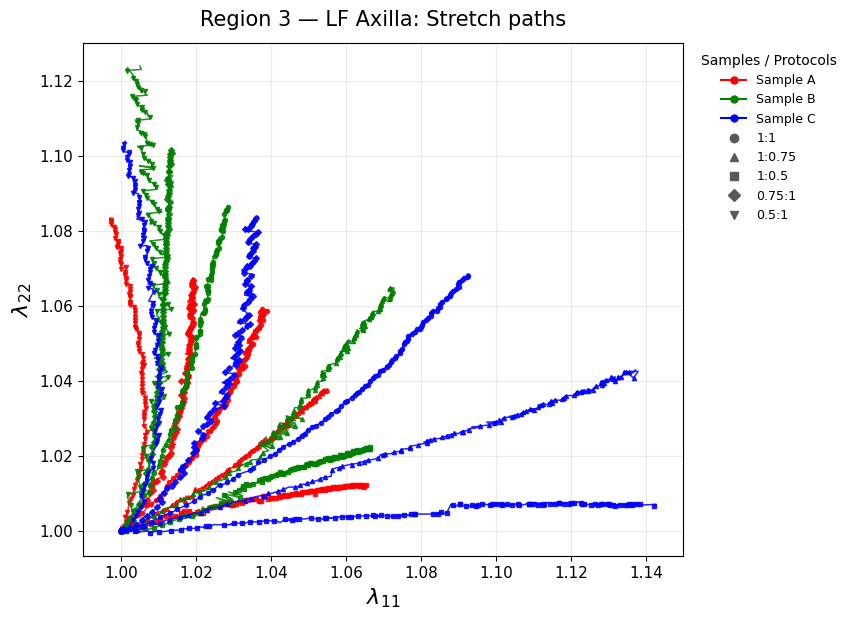

In [4]:
def plot_region_stretches_2d(region_id, point_step=3):
    if point_step < 1:
        raise ValueError("point_step must be at least 1.")
    region_df = get_plot_measurements(region_id)
    fig, ax = plt.subplots(figsize=(8.5, 6.3))
    plotted_pairs = []

    for sample in SAMPLES:
        for protocol in PROTOCOL_FILES:
            sub = region_df.loc[
                region_df["sample"].eq(sample)
                & region_df["protocol"].eq(protocol)
            ].sort_values("point_index")
            if sub.empty:
                continue
            plotted_pairs.append((sample, protocol))
            ax.plot(
                sub["lambda11"], sub["lambda22"],
                color=SAMPLE_COLORS[sample],
                marker=PROTOCOL_MARKERS[protocol],
                markersize=3.0,
                markevery=point_step,
                linewidth=1.1,
                alpha=0.85,
            )

    ax.set_xlabel(r"$\lambda_{11}$", fontsize=16)
    ax.set_ylabel(r"$\lambda_{22}$", fontsize=16)
    ax.set_title(
        f"Region {region_id} — {REGION_NAMES.get(region_id, '')}: Stretch paths",
        fontsize=15, pad=12,
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=11)

    # Shared legend: color = sample; marker = loading protocol.
    shown_samples = [s for s in SAMPLES if any(pair[0] == s for pair in plotted_pairs)]
    shown_protocols = [p for p in PROTOCOL_FILES if any(pair[1] == p for pair in plotted_pairs)]
    sample_handles = [
        Line2D([0], [0], color=SAMPLE_COLORS[s], lw=1.5, marker="o",
               markersize=5, label=f"Sample {s}")
        for s in shown_samples
    ]
    protocol_handles = [
        Line2D([0], [0], color="0.35", lw=0, marker=PROTOCOL_MARKERS[p],
               markersize=6, label=f"{PROTOCOL_LABELS[p]}")
        for p in shown_protocols
    ]
    ax.legend(
        handles=sample_handles + protocol_handles,
        fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1),
        title="Samples / Protocols", frameon=False,
    )
    fig.tight_layout()
    plt.show()



for region_id in STRETCH_PATH_REGIONS:
    plot_region_stretches_2d(region_id, point_step=PLOT_POINT_STEP)

In [5]:
def HGO(params, lambda11, lambda22):
    """HGO Cauchy stresses for [mu, k1, k2, phi]."""
    mu, k1, k2, phi = params

    c2 = np.cos(phi)**2
    s2 = np.sin(phi)**2

    I4 = lambda11**2 * c2 + lambda22**2 * s2

    inv = 1 / (lambda11**2 * lambda22**2)

    fiber = (
        4 * k1 * I4 * (I4 - 1)
        * np.exp(k2 * (I4 - 1)**2)
    )

    sigma11 = mu * (lambda11**2 - inv) + fiber * c2
    sigma22 = mu * (lambda22**2 - inv) + fiber * s2

    return sigma11, sigma22


def FFF(params, lambda11, lambda22):
    """Four-fiber-family Cauchy stresses in the two loading directions."""
    (mu, k1_22, k2_22, k1_11, k2_11,
     k1_diag, k2_diag, phi) = params

    c2 = np.cos(phi)**2
    s2 = np.sin(phi)**2

    I4 = lambda11**2 * c2 + lambda22**2 * s2

    E11 = lambda11**2 - 1
    E22 = lambda22**2 - 1
    Ediag = I4 - 1

    inv = 1 / (lambda11**2 * lambda22**2)

    diagonal = (
        2 * I4 * k1_diag * Ediag
        * np.exp(k2_diag * Ediag**2)
    )

    sigma11 = (
        mu * (lambda11**2 - inv)
        + lambda11**2 * k1_11 * E11
        * np.exp(k2_11 * E11**2)
        + diagonal * c2
    )

    sigma22 = (
        mu * (lambda22**2 - inv)
        + lambda22**2 * k1_22 * E22
        * np.exp(k2_22 * E22**2)
        + diagonal * s2
    )

    return sigma11, sigma22

In [6]:
# HGO parameters from the original regional notebooks
# Parameter order: [mu, k1, k2, phi]

HGO_parameters = {
    1: {
        "A": [752013.472, 110548.442, 855.558, 0.871],
        "B": [1161044.855, 270900.827, 1057.692, 2.282],
        "C": [1039386.322, 647524.380, 1207.781, 2.375]
    },
    2: {
        "A": [534240.579, 802575.343, 406.032, 2.429],
        "B": [826733.421, 436702.785, 1115.143, 2.539],
        "C": [1099809.377, 440353.454, 847.846, 0.352]
    },
    3: {
        "A": [389554.949, 435985.101, 180.074, 0.805],
        "B": [293072.958, 127359.981, 200.993, 2.457],
        "C": [775334.373, 7702.834, 187.297, 2.138]
    },
    4: {
        "A": [315843.441, 500910.396, 100.530, 0.883],
        "B": [55275.214, 1030041.211, 185.247, 0.787],
        "C": [411835.304, 217640.702, 349.774, 0.740]
    },
    5: {
        "A": [813129.455, 795221.672, 311.465, 0.770],
        "B": [706064.845, 272754.460, 523.592, 0.807],
        "C": [921793.514, 272409.420, 636.043, 0.837]
    },
    6: {
        "A": [614388.978, 643328.189, 212.871, 0.690],
        "B": [859988.326, 435622.315, 506.152, 0.732],
        "C": [308157.807, 430607.950, 238.866, 0.781]
    }
}


# FFF parameters from the original notebooks
# Order: [mu, k1_22, k2_22, k1_11, k2_11,
#         k1_diag, k2_diag, phi]

FFF_parameters = {
    1: {
        "A": [1.000, 741.107, 1005.773, 994155.488,
              24.501, 1335074.163, 386.322, 0.887],
        "B": [1.000, 137176.545, 334.382, 1586224.269,
              64.428, 2605551.357, 366.743, 0.903],
        "C": [1.000, 1213440.757, 15.253, 631172.929,
              192.656, 2686052.583, 823.225, 0.762]
    },
    2: {
        "A": [1.000, 78263.739, 281.067, 151622.772,
              809.070, 2512316.538, 283.673, 0.755],
        "B": [1.000, 751405.287, 140.377, 593237.105,
              810.459, 2058805.447, 624.320, 0.673],
        "C": [1.000, 1151347.894, 1.519, 665298.913,
              1261.466, 3034492.344, 73.468, 0.603]
    },
    3: {
        "A": [1.000, 1.000, 1.001, 534403.856,
              73.918, 1340090.018, 139.344, 0.845],
        "B": [1.000, 379963.871, 1.000, 499691.477,
              1.000, 491167.988, 150.808, 0.688],
        "C": [516966.060, 1.000, 1.000, 533083.452,
              1.000, 160868.519, 96.392, 1.002]
    },
    4: {
        "A": [1.000, 1.000, 1.000, 490859.594,
              11.934, 1343465.842, 86.212, 0.898],
        "B": [1.000, 25796.442, 47.120, 21824.166,
              48.655, 2017489.201, 190.294, 0.795],
        "C": [20230.435, 466150.138, 1.000, 12805.071,
              1.000, 772140.370, 288.656, 0.735]
    },
    5: {
        "A": [1.000, 638277.669, 28.711, 29726.195,
              432.391, 2848386.193, 222.766, 0.756],
        "B": [1.000, 350361.430, 46.863, 857890.513,
              43.927, 1258138.016, 367.455, 0.813],
        "C": [1.000, 1.000, 1.000, 1446190.070,
              23.293, 2253577.956, 156.322, 0.937]
    },
    6: {
        "A": [1.000, 426361.310, 82.644, 1178349.940,
            98.892, 1850071.690, 159.573, 0.753],
        "B": [1.000, 927295.803, 1.000, 1163013.345,
            1.000, 1707319.920, 381.948, 0.736],
        "C": [1.000, 1.000, 1.000, 934925.204,
            3.387, 1148637.040, 207.557, 0.796]
    }
}

MODEL_DEFINITIONS = {"HGO": (HGO, HGO_parameters), "FFF": (FFF, FFF_parameters)}
PARAMETER_NAMES = {
    "HGO": ["mu", "k1", "k2", "phi"],
    "FFF": ["mu", "k1_22", "k2_22", "k1_11", "k2_11", "k1_diag", "k2_diag", "phi"],
}

for model_name, (_, parameters) in MODEL_DEFINITIONS.items():
    if set(parameters) != set(REGION_NAMES):
        raise ValueError(f"{model_name}: expected fitted parameters for all six regions.")
    for region_id, samples in parameters.items():
        if set(samples) != set(SAMPLES):
            raise ValueError(f"{model_name}, Region {region_id}: expected fits for A, B and C.")
        for sample, values in samples.items():
            if len(values) != len(PARAMETER_NAMES[model_name]) or not np.isfinite(values).all():
                raise ValueError(f"{model_name}, Region {region_id}, Sample {sample}: invalid fit.")

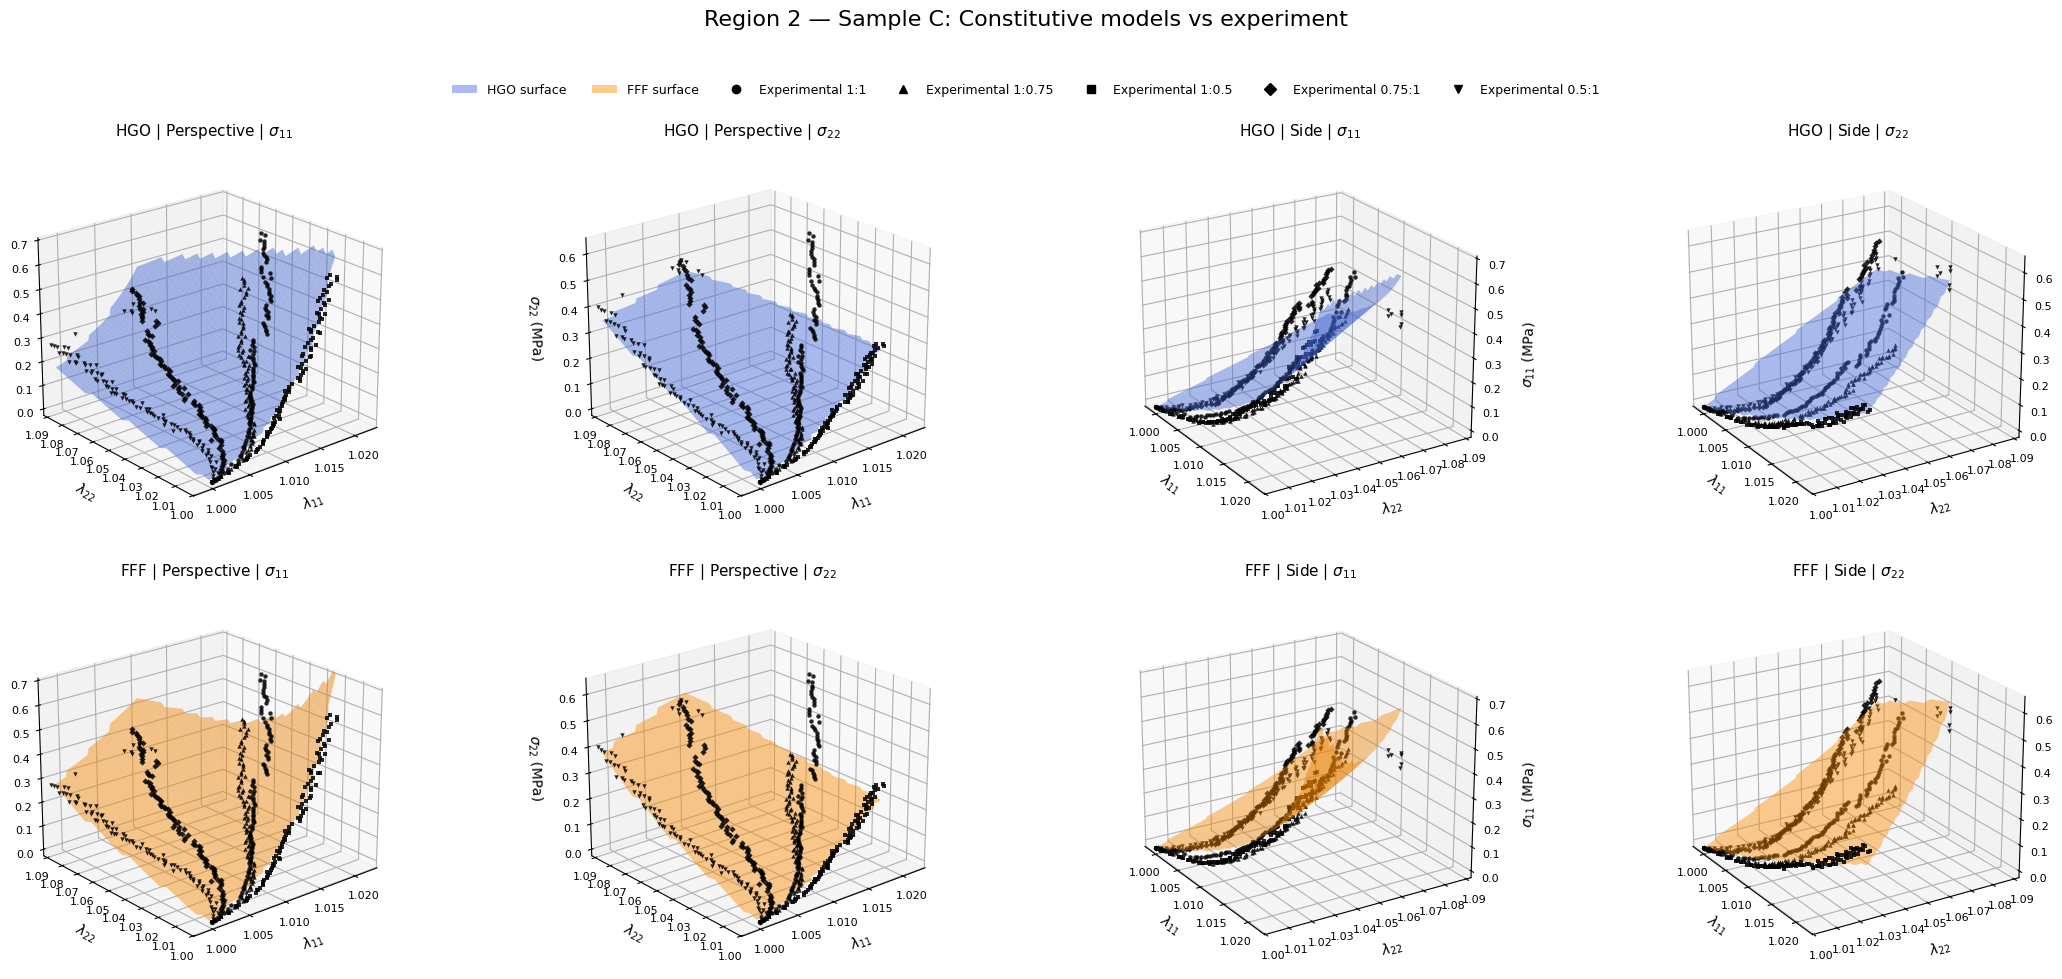

In [7]:
def plot_sample_model_surfaces(region_id, sample, point_step=3, grid_n=55,
                               stress_window="experimental"):
    df = get_plot_measurements(region_id, sample)
    included_protocols = [p for p in PROTOCOL_FILES if df["protocol"].eq(p).any()]
    if point_step < 1 or grid_n < 3:
        raise ValueError("point_step must be >= 1 and grid_n >= 3.")
    if stress_window not in ("experimental", "combined"):
        raise ValueError("stress_window must be 'experimental' or 'combined'.")

    models = [
        ("HGO", HGO, HGO_parameters[region_id][sample], "royalblue"),
        ("FFF", FFF, FFF_parameters[region_id][sample], "darkorange"),
    ]

    x = np.linspace(df["lambda11"].min(), df["lambda11"].max(), grid_n)
    y = np.linspace(df["lambda22"].min(), df["lambda22"].max(), grid_n)
    X, Y = np.meshgrid(x, y)

    # Show each surface only over the sample's observed stretch domain.
    observed_xy = df[["lambda11", "lambda22"]].drop_duplicates().to_numpy()
    if len(observed_xy) < 3:
        raise ValueError("At least 3 distinct measured stretch states are required.")
    hull = Delaunay(observed_xy)
    inside = hull.find_simplex(np.column_stack([X.ravel(), Y.ravel()]))
    inside = inside.reshape(X.shape) >= 0

    # Evaluate both models once; the two camera angles reuse these same surfaces.
    predictions = {}
    for name, model, params, _ in models:
        with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
            z11, z22 = model(params, X, Y)
        predictions[name] = {
            "11": np.where(inside & np.isfinite(z11), z11 / 1e6, np.nan),
            "22": np.where(inside & np.isfinite(z22), z22 / 1e6, np.nan),
        }

    # Same axis limits for both views and both models in each direction.
    zlimits = {}
    for direction in ("11", "22"):
        measured = df[f"sigma{direction}"].to_numpy(dtype=float) / 1e6
        valid = measured[np.isfinite(measured)]
        if stress_window == "combined":
            for name in ("HGO", "FFF"):
                predicted = predictions[name][direction]
                valid = np.concatenate([valid, predicted[np.isfinite(predicted)]])
        zlo, zhi = float(valid.min()), float(valid.max())
        pad = max((zhi - zlo) * 0.04, 0.005)
        zlimits[direction] = (zlo - pad, zhi + pad)

    # Rows = constitutive models (HGO, FFF).
    # Columns = perspective sigma11/sigma22 and side sigma11/sigma22.
    fig = plt.figure(figsize=(22, 10))
    for model_i, (name, _, _, color) in enumerate(models):
        for view_i, (view_name, elev, azim) in enumerate(CAMERA_VIEWS):
            for dir_i, direction in enumerate(("11", "22")):
                col = 2 * view_i + dir_i
                ax = fig.add_subplot(2, 4, 4 * model_i + col + 1, projection="3d")

                # Fitted surface. The camera changes, not the data or prediction.
                ax.plot_surface(
                    X, Y, predictions[name][direction],
                    color=color, alpha=0.45, linewidth=0,
                    antialiased=True, rcount=grid_n, ccount=grid_n,
                )

                # Protocol-specific markers for measured stress points.
                for protocol in included_protocols:
                    sub = df.loc[df["protocol"] == protocol].sort_values("point_index")
                    if sub.empty:
                        continue
                    ax.scatter(
                        sub["lambda11"].to_numpy()[::point_step],
                        sub["lambda22"].to_numpy()[::point_step],
                        sub[f"sigma{direction}"].to_numpy()[::point_step] / 1e6,
                        color="black", marker=PROTOCOL_MARKERS[protocol],
                        s=10, alpha=0.85, depthshade=False, linewidths=0,
                    )

                ax.set_title(f"{name} | {view_name} | " + rf"$\sigma_{{{direction}}}$",
                             fontsize=11, pad=10)
                ax.set_xlabel(r"$\lambda_{11}$", labelpad=1)
                ax.set_ylabel(r"$\lambda_{22}$", labelpad=1)
                ax.set_zlabel(rf"$\sigma_{{{direction}}}$ (MPa)", labelpad=2)
                ax.set_xlim(float(x.min()), float(x.max()))
                ax.set_ylim(float(y.min()), float(y.max()))
                ax.set_zlim(*zlimits[direction])
                ax.view_init(elev=elev, azim=azim)
                ax.set_box_aspect((1, 1, 0.8))
                ax.tick_params(labelsize=8, pad=0)

    legend_handles = [
        Patch(facecolor="royalblue", alpha=0.45, label="HGO surface"),
        Patch(facecolor="darkorange", alpha=0.45, label="FFF surface"),
    ]
    legend_handles += [
        Line2D([0], [0], color="black", linestyle="none",
               marker=PROTOCOL_MARKERS[p], markersize=6,
               label=f"Experimental {PROTOCOL_LABELS[p]}")
        for p in included_protocols
    ]
    fig.suptitle(
        f"Region {region_id} — Sample {sample}: Constitutive models vs experiment",
        fontsize=16, y=0.995,
    )
    fig.legend(
        handles=legend_handles, loc="upper center", ncol=len(legend_handles),
        bbox_to_anchor=(0.5, 0.932), frameon=False, fontsize=9,
    )
    fig.subplots_adjust(
        left=0.01, right=0.99, bottom=0.035, top=0.855,
        wspace=0.07, hspace=0.16,
    )
    plt.show()



for region_id, sample in SINGLE_SAMPLE_FITS:
    plot_sample_model_surfaces(
        region_id, sample, point_step=PLOT_POINT_STEP,
        stress_window=SINGLE_SAMPLE_STRESS_WINDOW,
    )

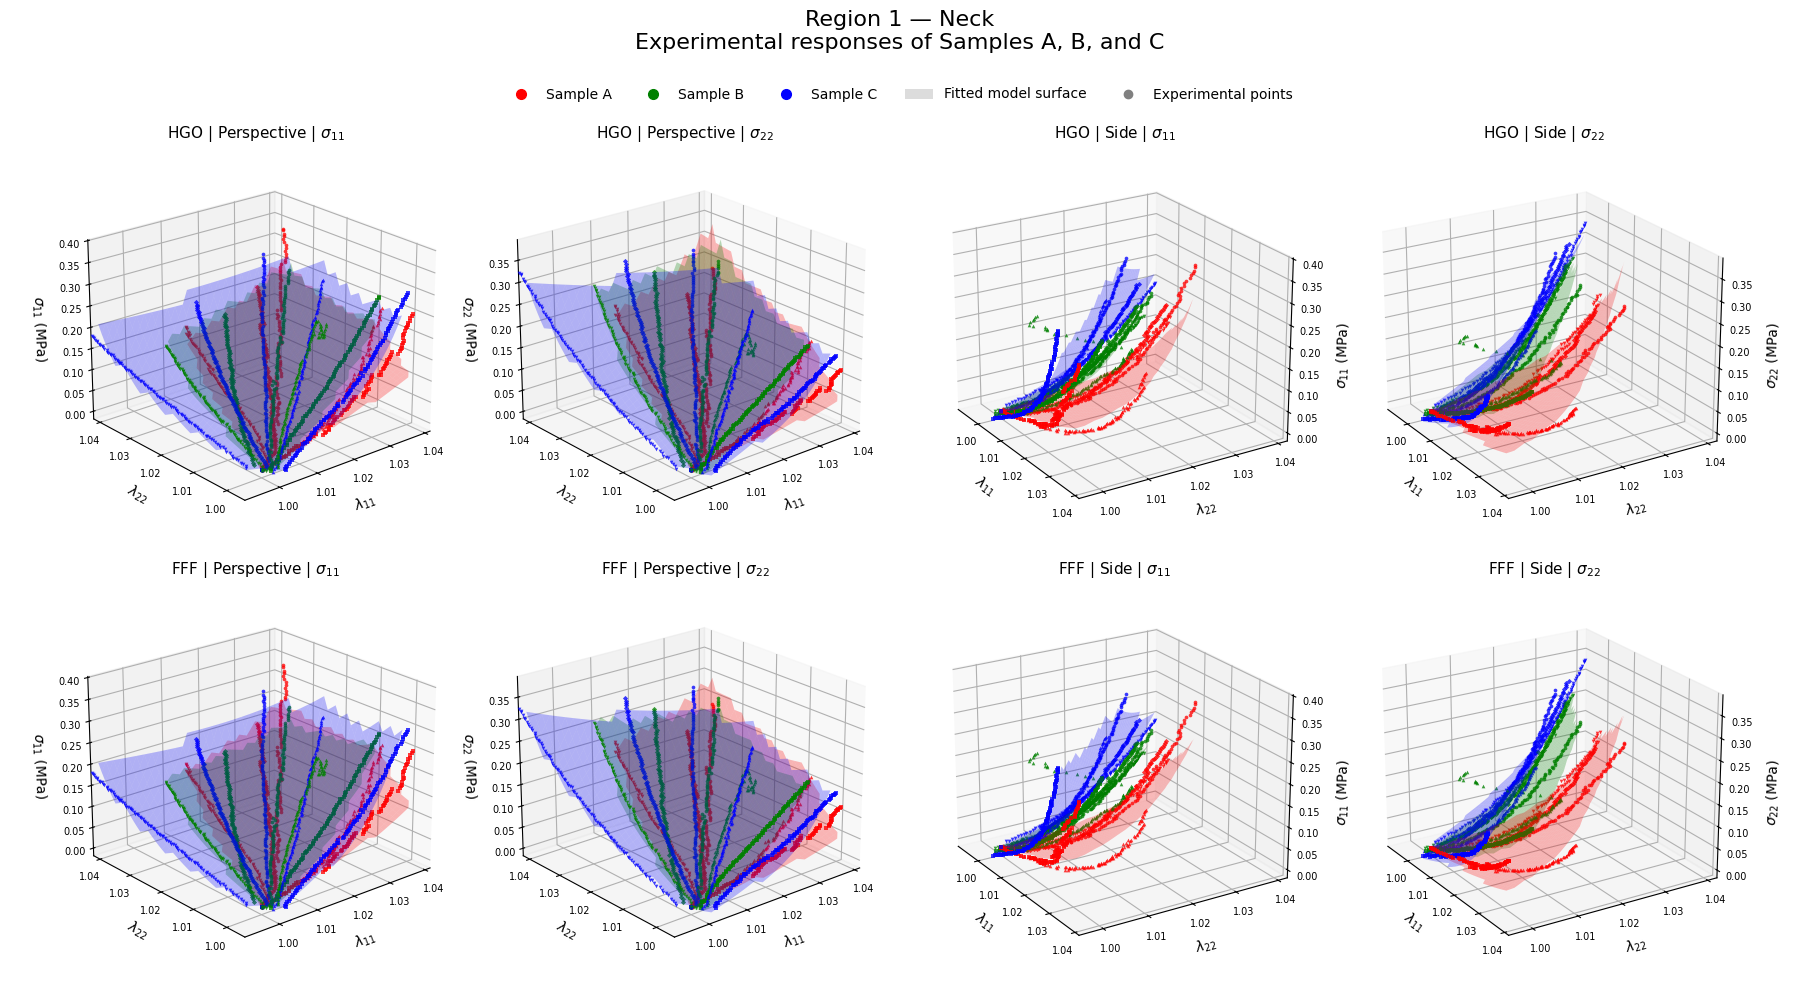

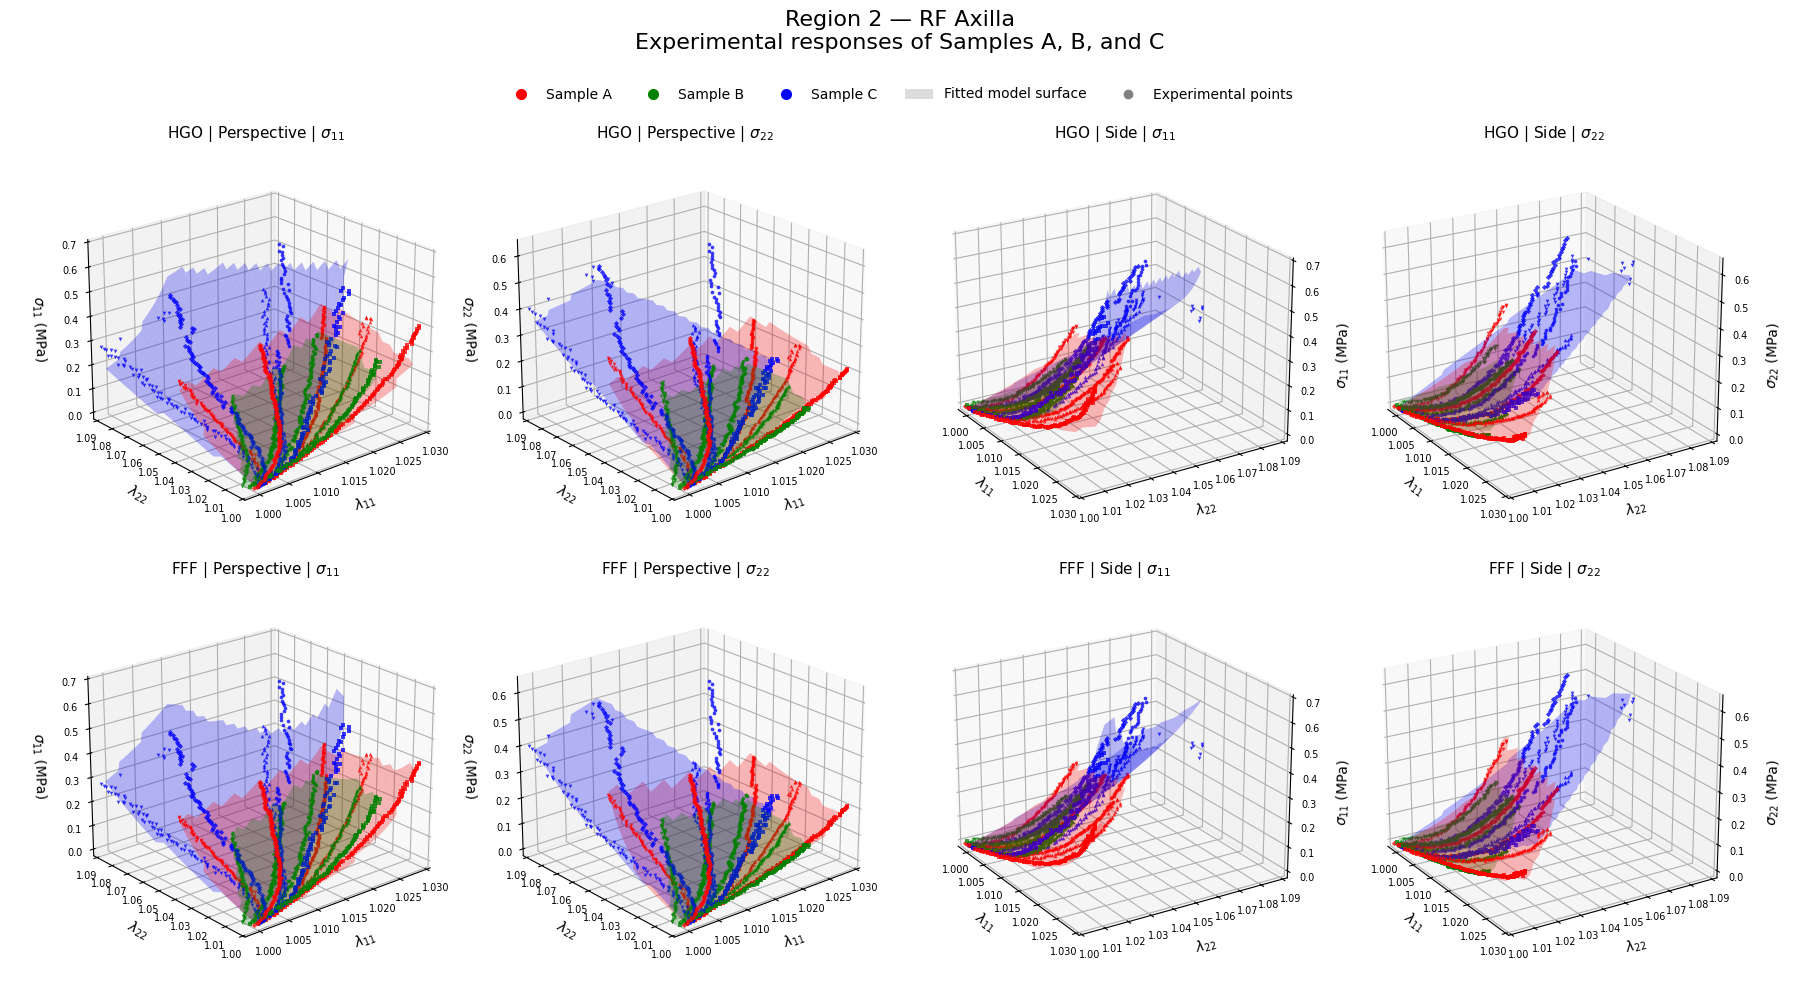

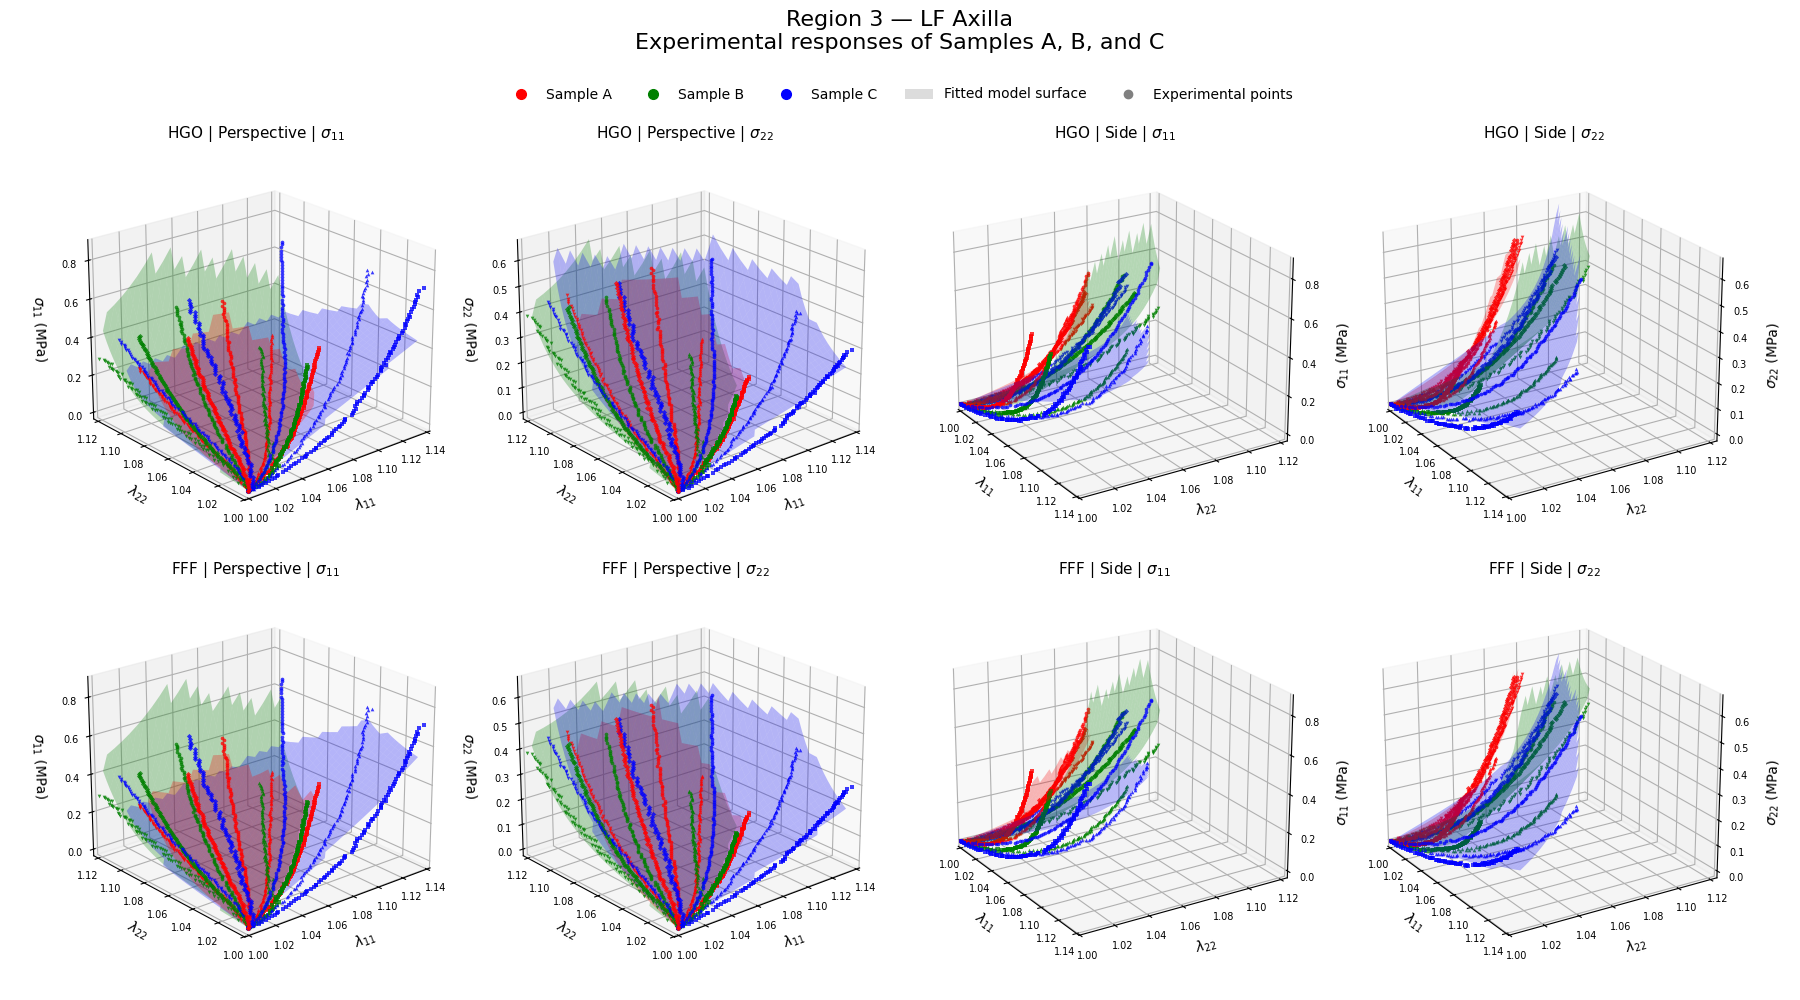

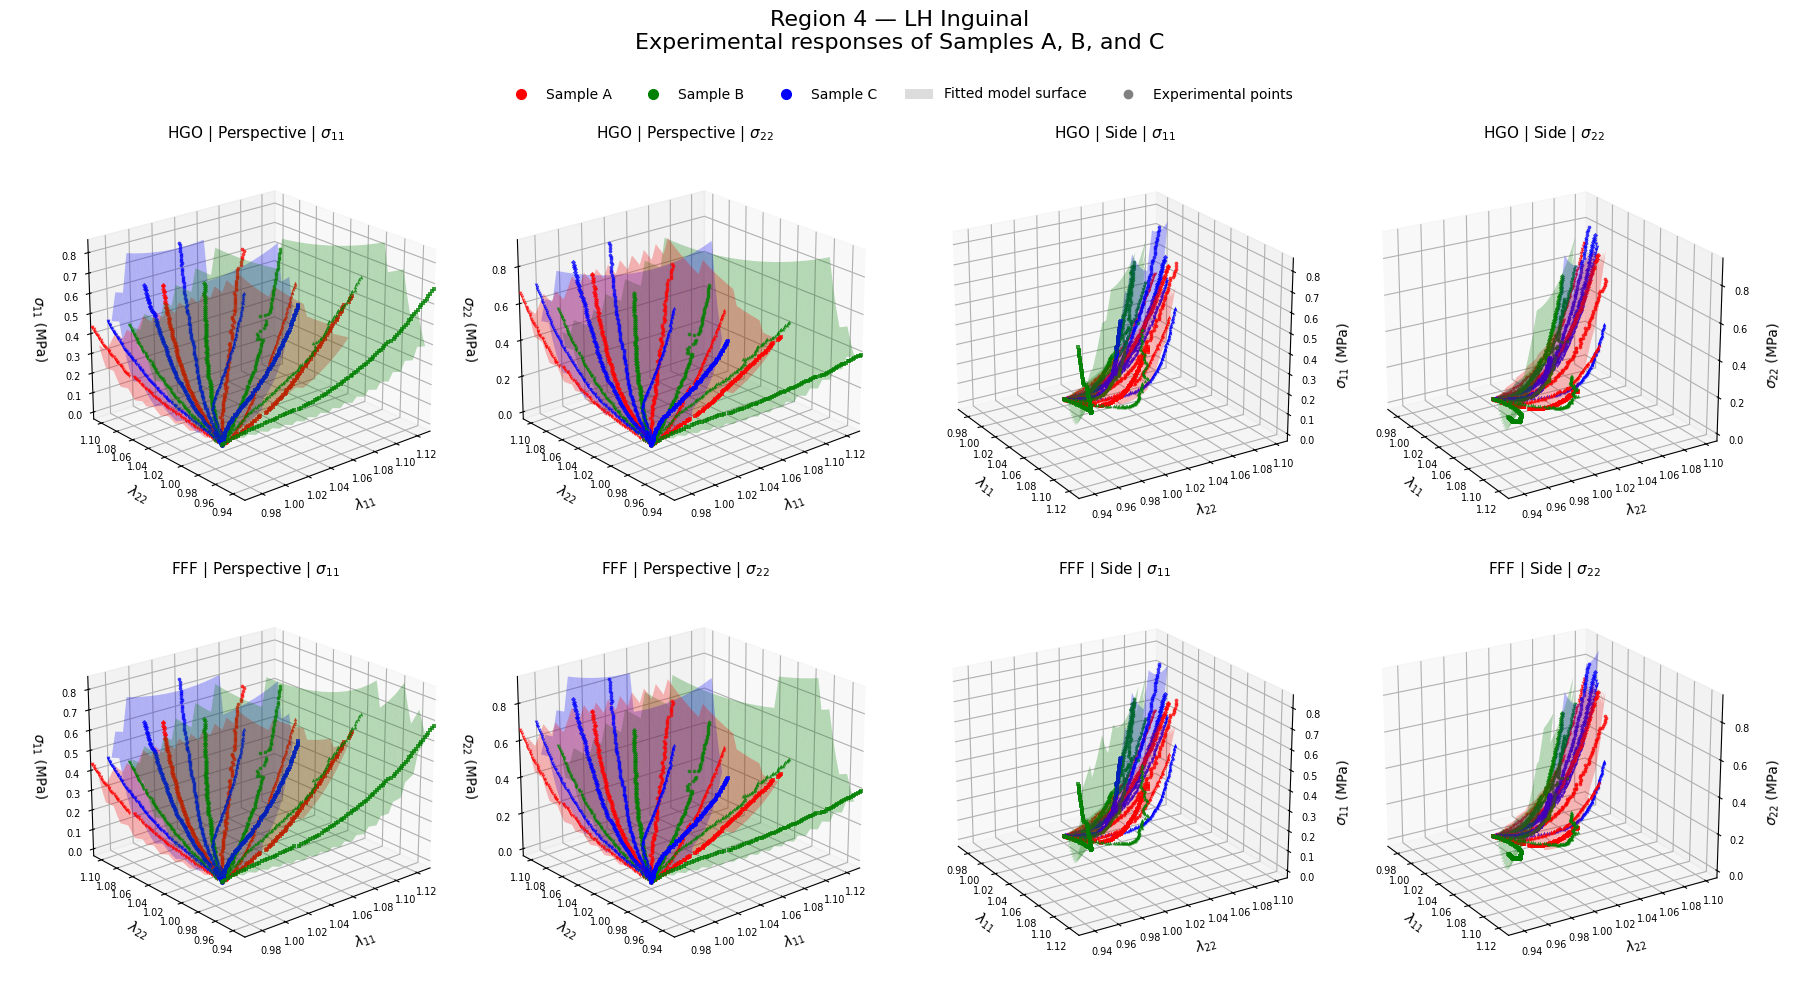

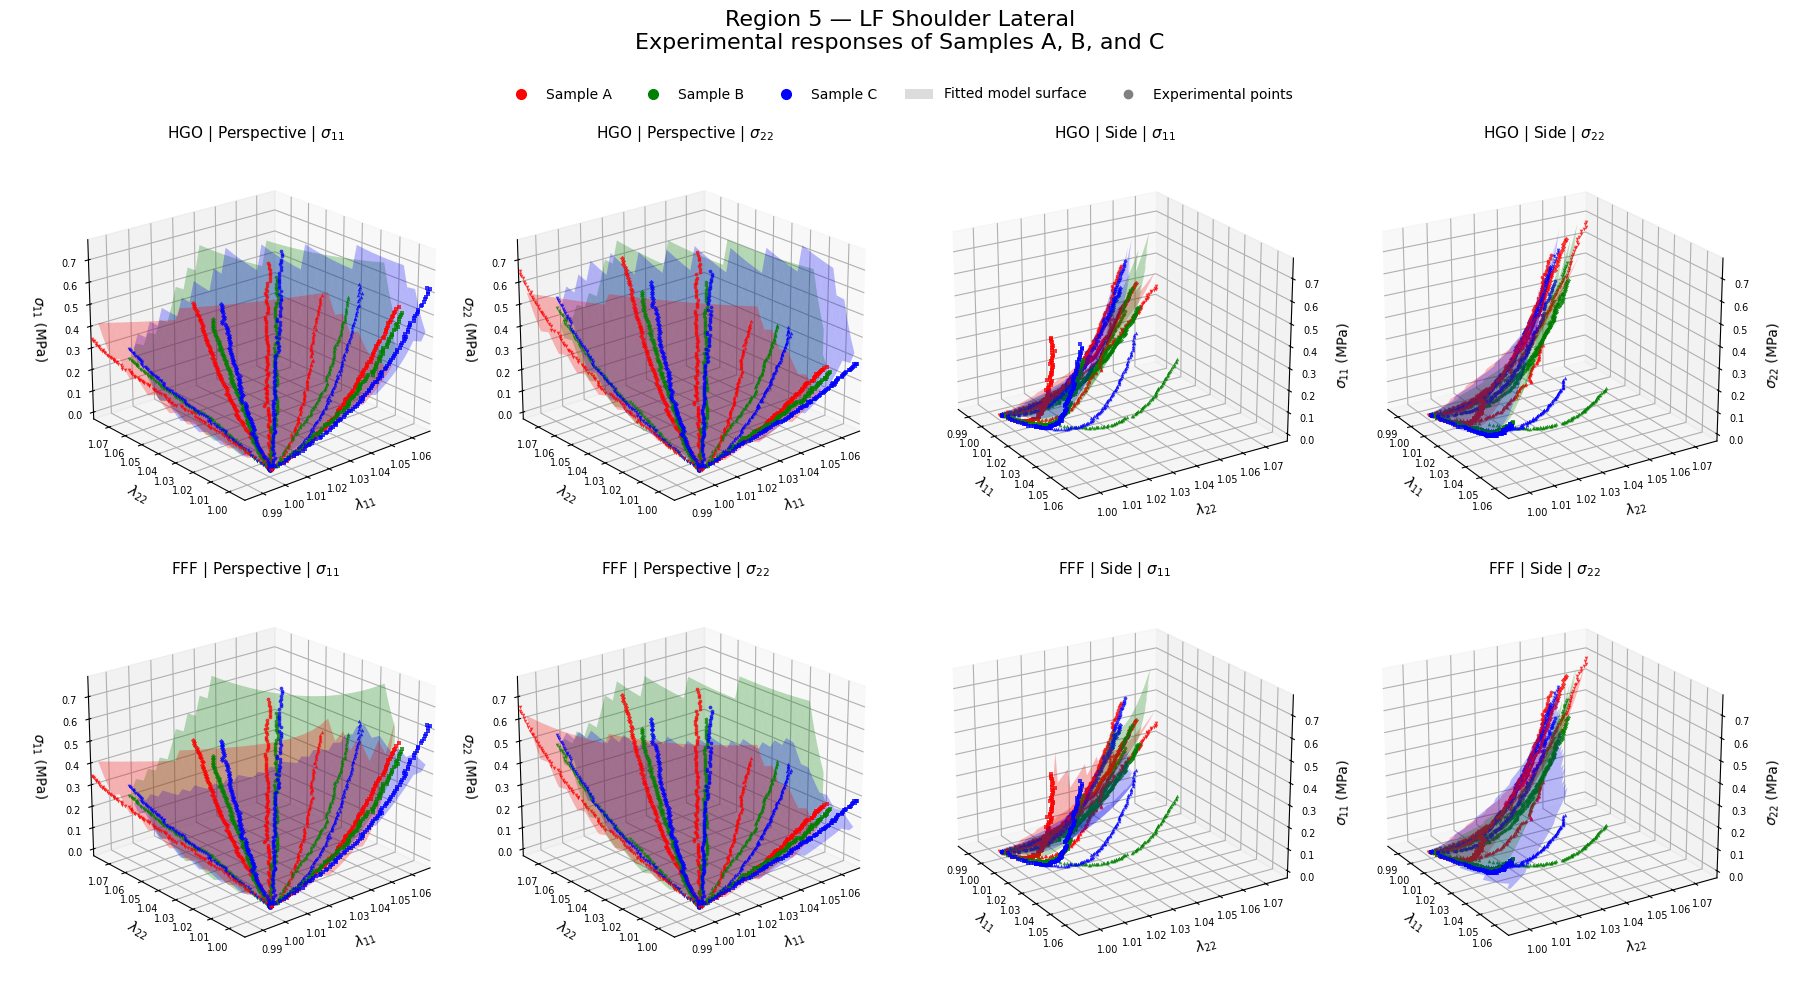

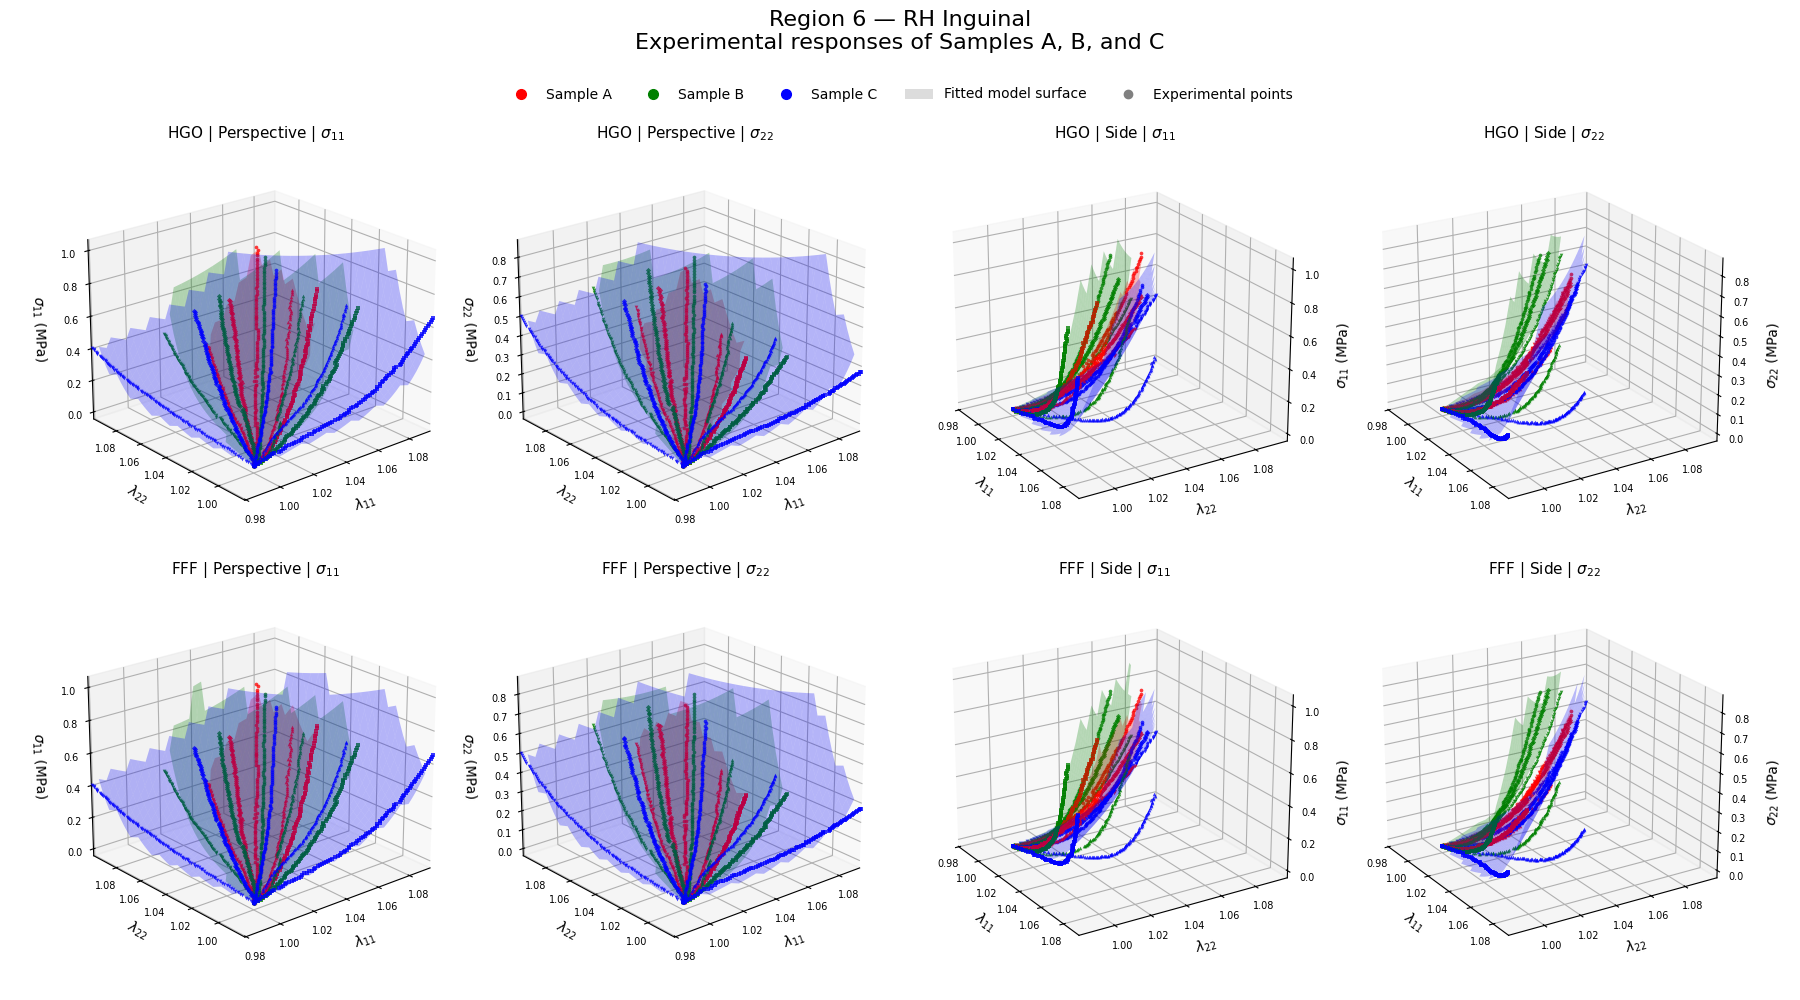

In [8]:
def plot_region_abc_surfaces(region_id, grid_n=45, point_step=3):

    region = combined_df[
        combined_df["region_id"] == region_id
    ].copy()

    if region.empty:
        raise ValueError(f"No data for region {region_id}")

    samples = {
        s: region[region["sample"] == s].copy()
        for s in SAMPLES
    }

    if any(df.empty for df in samples.values()):
        raise ValueError("Missing A, B, or C sample.")

    models = [(name, model, params) for name, (model, params) in MODEL_DEFINITIONS.items()]

    # One common stretch grid across A, B, and C
    x = np.linspace(
        region["lambda11"].min(),
        region["lambda11"].max(), grid_n
    )
    y = np.linspace(
        region["lambda22"].min(),
        region["lambda22"].max(), grid_n
    )

    X, Y = np.meshgrid(x, y)
    grid_points = np.column_stack([X.ravel(), Y.ravel()])

    # Each sample's own measured stretch domain
    in_domain = {}

    for sample, df in samples.items():
        hull = Delaunay(
            df[["lambda11", "lambda22"]].to_numpy()
        )
        in_domain[sample] = (
            hull.find_simplex(grid_points)
            .reshape(X.shape) >= 0
        )

    # Common stress limits across A/B/C, models and views
    zlimits = {}

    for direction in ["11", "22"]:
        stresses = (
            region[f"sigma{direction}"].to_numpy() / 1e6
        )

        zmin = float(stresses.min())
        zmax = float(stresses.max())

        padding = max(0.04 * (zmax - zmin), 0.005)

        zlimits[direction] = (
            zmin - padding,
            zmax + padding
        )

    # Evaluate all fitted surfaces once
    surfaces = {}

    for model_name, model_fun, params_dict in models:

        for sample in SAMPLES:

            params = params_dict[region_id][sample]

            with np.errstate(over="ignore", invalid="ignore"):
                surfaces[(model_name, sample)] = model_fun(
                    params, X, Y
                )

    # Two rows (models), four columns (views/directions)
    fig = plt.figure(figsize=(18, 10))

    for model_i, (model_name, _, _) in enumerate(models):

        for view_i, (view_name, elev, azim) in enumerate(CAMERA_VIEWS):

            for dir_i, direction in enumerate(["11", "22"]):

                col = 2 * view_i + dir_i

                ax = fig.add_subplot(
                    2, 4, 4 * model_i + col + 1,
                    projection="3d"
                )

                zlow, zhigh = zlimits[direction]

                for sample in SAMPLES:

                    color = SAMPLE_COLORS[sample]
                    df = samples[sample]

                    Z11, Z22 = surfaces[(model_name, sample)]

                    Z = (
                        Z11 if direction == "11" else Z22
                    ) / 1e6

                    # Surface display only within its measured
                    # stretch domain and the regional stress window.
                    # This does not change the analysis data.
                    visible = (
                        in_domain[sample]
                        & np.isfinite(Z)
                        & (Z >= zlow)
                        & (Z <= zhigh)
                    )

                    Z_display = np.where(
                        visible, Z, np.nan
                    )

                    ax.plot_surface(
                        X, Y, Z_display,
                        color=color,
                        alpha=0.27,
                        linewidth=0,
                        antialiased=True,
                        shade=True,
                        rcount=grid_n,
                        ccount=grid_n
                    )

                    # Experimental points for all five protocols
                    for protocol in PROTOCOL_FILES:

                        p = df[
                            df["protocol"] == protocol
                        ].sort_values("point_index")

                        ax.scatter(
                            p["lambda11"].to_numpy()[::point_step],
                            p["lambda22"].to_numpy()[::point_step],
                            (
                                p[f"sigma{direction}"].to_numpy()
                                / 1e6
                            )[::point_step],
                            color=color,
                            marker=PROTOCOL_MARKERS[protocol],
                            s=7,
                            alpha=0.77,
                            depthshade=False,
                            linewidths=0
                        )

                ax.set_title(
                    f"{model_name} | {view_name} | "
                    + rf"$\sigma_{{{direction}}}$",
                    fontsize=11,
                    pad=9
                )

                ax.set_xlabel(r"$\lambda_{11}$", labelpad=0)
                ax.set_ylabel(r"$\lambda_{22}$", labelpad=0)
                ax.set_zlabel(
                    rf"$\sigma_{{{direction}}}$ (MPa)",
                    labelpad=1
                )

                ax.set_xlim(x.min(), x.max())
                ax.set_ylim(y.min(), y.max())
                ax.set_zlim(zlow, zhigh)

                ax.tick_params(labelsize=7, pad=0)
                ax.view_init(elev=elev, azim=azim)
                ax.set_box_aspect((1, 1, 0.8))

    # Sample legend
    legend_handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="none",
            markersize=7,
            color=SAMPLE_COLORS[s],
            label=f"Sample {s}"
        )
        for s in SAMPLES
    ]

    legend_handles += [
        Patch(
            facecolor="gray",
            alpha=0.27,
            label="Fitted model surface"
        ),
        Line2D(
            [0], [0],
            marker="o",
            linestyle="none",
            color="gray",
            label="Experimental points"
        )
    ]

    fig.suptitle(
        f"Region {region_id} — "
        f"{REGION_NAMES.get(region_id, '')}\n"
        "Experimental responses of Samples A, B, and C",
        fontsize=16,
        y=0.99
    )

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        ncol=5,
        bbox_to_anchor=(0.5, 0.925),
        frameon=False,
        fontsize=10
    )

    fig.subplots_adjust(
        left=0.025,
        right=0.975,
        bottom=0.03,
        top=0.85,
        wspace=0.02,
        hspace=0.14
    )

    plt.show()



shell = get_ipython()
if shell is not None:
    shell.run_line_magic("config", 'InlineBackend.print_figure_kwargs = {"bbox_inches": None}')

for region_id in REGIONAL_OVERLAYS:
    plot_region_abc_surfaces(region_id, point_step=PLOT_POINT_STEP)

In [9]:
paired_data = (
    combined_df.pivot(
        index=["region_id", "protocol", "point_index"],
        columns="sample",
        values=STRETCH_COLUMNS + STRESS_COLUMNS,
    )
    .swaplevel(axis=1)
    .sort_index()
)
if (
    set(paired_data.columns.get_level_values("sample")) != set(SAMPLES)
    or not np.isfinite(paired_data.to_numpy(dtype=float)).all()
):
    raise ValueError("Samples A, B and C require finite measurements at matching protocol indices.")

# Constitutive prediction scores for both models use the same protocol exclusions.
REGIONS_EXCLUDING_1_075 = (1, 3, 4, 5, 6)
MODEL_PROTOCOL_EXCLUSIONS = {
    model_name: {region: ("1_0.75",) for region in REGIONS_EXCLUDING_1_075}
    for model_name in MODEL_DEFINITIONS
}
PREDICTORS_FOR_B = ("A", "C")
SCORE_DIRECTIONS = ("11", "22", "Combined")
METRIC_COLUMNS = ["NRMSE (%)", "R²"]


def get_excluded_protocols(model_name, region_id):
    exclusions = MODEL_PROTOCOL_EXCLUSIONS[model_name].get(region_id, ())
    if isinstance(exclusions, str):
        exclusions = (exclusions,)
    invalid = set(exclusions).difference(PROTOCOL_FILES)
    if invalid:
        raise ValueError(f"Invalid exclusions for {model_name}, Region {region_id}: {sorted(invalid)}")
    return list(exclusions)

In [10]:
def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()

    if y_true.shape != y_pred.shape or y_true.size == 0:
        raise ValueError("Reference and predicted arrays must match and be non-empty.")
    if not (np.isfinite(y_true).all() and np.isfinite(y_pred).all()):
        raise ValueError("Non-finite reference or predicted stresses detected.")

    residuals = y_true - y_pred
    rmse = np.sqrt(np.mean(residuals**2))
    stress_range = np.ptp(y_true)
    nrmse = 100 * rmse / stress_range if stress_range > 0 else np.nan

    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
    return nrmse, r2


def score_stresses(reference, predicted, direction):
    if direction == "Combined":
        actual, estimate = reference.T.ravel(), predicted.T.ravel()
    else:
        component = {"11": 0, "22": 1}[direction]
        actual, estimate = reference[:, component], predicted[:, component]
    nrmse, r2 = calculate_metrics(actual, estimate) if len(actual) else (np.nan, np.nan)
    return {"Direction": direction, "N states": len(reference), "NRMSE (%)": nrmse, "R²": r2}


def make_score_table(scores, row_keys):
    def format_scores(values):
        return [f"{nrmse:.2f}% / {r2:.2f}" for nrmse, r2 in values[METRIC_COLUMNS].to_numpy()]

    row_order = scores[row_keys].drop_duplicates().set_index(row_keys).index
    table = (
        scores.assign(Score=format_scores(scores))
        .pivot(index=row_keys, columns="Region", values="Score")
        .reindex(row_order)
        .rename(columns=lambda region: f"Region {region}")
    )
    table.columns.name = "NRMSE (%) / R²"
    medians = scores.groupby(row_keys)[METRIC_COLUMNS].median().reindex(row_order)
    table["Median"] = format_scores(medians)
    return table

In [11]:
def geometric_mean_nonnegative(a, b):
    """Log-space geometric mean, with exact zero-preserving behavior."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if a.shape != b.shape:
        raise ValueError("A and C parameter arrays must have identical shapes.")
    if not (np.isfinite(a).all() and np.isfinite(b).all()):
        raise ValueError("Non-finite fitted parameter encountered.")
    if (a < 0).any() or (b < 0).any():
        raise ValueError("Geometric averaging requires nonnegative coefficients.")
    averaged = np.zeros_like(a)
    positive = (a > 0) & (b > 0)
    averaged[positive] = np.exp(
        0.5 * (np.log(a[positive]) + np.log(b[positive]))
    )
    return averaged


def canonical_hgo_phi(phi):
    """Represent equivalent HGO fiber orientations by phi in [0, pi/2]."""
    phi = float(phi)
    if not np.isfinite(phi) or not (0 <= phi <= np.pi):
        raise ValueError(f"HGO phi must be in [0, pi], got {phi}.")
    return min(phi, np.pi - phi)



def make_averaged_parameters(model_name, first, second, method, *, fold_hgo=True):
    """Average coefficients and take the arithmetic mean of the fiber angles."""
    first, second = np.asarray(first, dtype=float), np.asarray(second, dtype=float)
    expected_shape = (len(PARAMETER_NAMES[model_name]),)
    if first.shape != expected_shape or second.shape != expected_shape:
        raise ValueError(f"Wrong parameter shape for {model_name}.")
    if not (np.isfinite(first).all() and np.isfinite(second).all()):
        raise ValueError(f"Invalid parameters for {model_name}.")

    phi_first, phi_second = first[-1], second[-1]
    if model_name == "HGO" and fold_hgo:
        phi_first = canonical_hgo_phi(phi_first)
        phi_second = canonical_hgo_phi(phi_second)

    if method == "Arithmetic":
        coefficients = 0.5 * (first[:-1] + second[:-1])
    elif method == "Geometric":
        coefficients = geometric_mean_nonnegative(first[:-1], second[:-1])
    else:
        raise ValueError(f"Unknown parameter mean {method!r}.")
    return np.r_[coefficients, 0.5 * (phi_first + phi_second)]


def direct_responses(region_data, target, predictors):
    first, second = predictors
    actual = region_data[target][STRESS_COLUMNS].to_numpy(dtype=float)
    predicted = (
        region_data[first][STRESS_COLUMNS] + region_data[second][STRESS_COLUMNS]
    ).to_numpy(dtype=float) / 2
    return actual, predicted


def equivalent_stretch_paths(region_data, region_id, model_name, predictors, *, include_excluded=False):
    first, second = predictors
    excluded = () if include_excluded else get_excluded_protocols(model_name, region_id)
    paths = {}
    for protocol, block in region_data.groupby(level="protocol", sort=False):
        if protocol in excluded:
            continue
        first_max = block[first][STRETCH_COLUMNS].max().to_numpy(dtype=float)
        second_max = block[second][STRETCH_COLUMNS].max().to_numpy(dtype=float)
        paths[protocol] = np.linspace([1.0, 1.0], (first_max + second_max) / 2, num=len(block))
    if not paths:
        raise ValueError(f"Region {region_id}, {model_name}: no retained protocols.")
    return paths


def average_model_responses(model, first_params, second_params, lambda11, lambda22):
    first_stresses = model(first_params, lambda11, lambda22)
    second_stresses = model(second_params, lambda11, lambda22)
    return tuple((first + second) / 2 for first, second in zip(first_stresses, second_stresses))


def evaluate_stresses(evaluate, stretch):
    with np.errstate(over="raise", invalid="raise", divide="raise"):
        return np.column_stack(evaluate(*stretch.T))


def model_comparison(region_data, region_id, model_name, target, predictors):
    model, parameters = MODEL_DEFINITIONS[model_name]
    first_params, second_params = (parameters[region_id][sample] for sample in predictors)
    mean_params = make_averaged_parameters(model_name, first_params, second_params, "Arithmetic")
    fitted_target = partial(model, parameters[region_id][target])
    prediction_functions = {
        "Model response": partial(average_model_responses, model, first_params, second_params),
        "Parameters (arithmetic)": partial(model, mean_params),
    }

    paths = equivalent_stretch_paths(region_data, region_id, model_name, predictors)
    stretch = np.concatenate(tuple(paths.values()))
    try:
        reference = evaluate_stresses(fitted_target, stretch)
        predictions = {
            method: evaluate_stresses(evaluate, stretch)
            for method, evaluate in prediction_functions.items()
        }
    except FloatingPointError as error:
        raise FloatingPointError(
            f"Region {region_id}, {model_name}, target {target}: stress evaluation "
            "failed on the equivalent stretches."
        ) from error

    return {
        "paths": paths,
        "stretch": stretch,
        "reference": reference,
        "predictions": predictions,
        "fitted_target": fitted_target,
        "prediction_functions": prediction_functions,
    }

In [12]:
def predict_target(region_id, target, predictors):
    region_data = paired_data.loc[region_id]
    case = {
        "Region": region_id,
        "Target": target,
        "Prediction": f"{'+'.join(predictors)} → {target}",
    }
    actual, predicted = direct_responses(region_data, target, predictors)
    rows = [
        {
            **case, "Method": "Direct response", "Model": "—",
            "Reference": f"Experimental {target} (index)",
            **score_stresses(actual, predicted, direction),
        }
        for direction in SCORE_DIRECTIONS
    ]

    comparisons = {}
    for model_name in MODEL_DEFINITIONS:
        comparison = model_comparison(region_data, region_id, model_name, target, predictors)
        comparisons[model_name] = comparison
        for method, predicted in comparison["predictions"].items():
            rows.extend(
                {
                    **case, "Method": method, "Model": model_name,
                    "Reference": f"Fitted {target} (equivalent)",
                    **score_stresses(comparison["reference"], predicted, direction),
                }
                for direction in SCORE_DIRECTIONS
            )
    return rows, comparisons


b_rows = []
b_comparisons = {}
for region_id in REGION_NAMES:
    scores, comparisons = predict_target(region_id, "B", PREDICTORS_FOR_B)
    b_rows.extend(scores)
    for model_name, comparison in comparisons.items():
        b_comparisons[region_id, model_name] = comparison

equivalent_averaging_results = pd.DataFrame(b_rows)
equivalent_averaging_table = make_score_table(
    equivalent_averaging_results, ["Method", "Model", "Reference", "Direction"],
)
display(equivalent_averaging_table)

NRMSE (%) / R²                                                        Region 1  \
Method                  Model Reference              Direction                   
Direct response         —     Experimental B (index) 11           5.25% / 0.96   
                                                     22           4.89% / 0.96   
                                                     Combined     4.94% / 0.96   
Model response          HGO   Fitted B (equivalent)  11           8.73% / 0.82   
                                                     22           5.24% / 0.92   
                                                     Combined     5.66% / 0.88   
Parameters (arithmetic) HGO   Fitted B (equivalent)  11           2.69% / 0.98   
                                                     22           2.90% / 0.98   
                                                     Combined     2.44% / 0.98   
Model response          FFF   Fitted B (equivalent)  11          11.84% / 0.77   
                                                     22           6.24% / 0.90   
                                                     Combined     6.44% / 0.85   
Parameters (arithmetic) FFF   Fitted B (equivalent)  11           5.45% / 0.95   
                                                     22         22.19% / -0.32   
                                                     Combined    15.84% / 0.11   

NRMSE (%) / R²                                                        Region 2  \
Method                  Model Reference              Direction                   
Direct response         —     Experimental B (index) 11          17.27% / 0.49   
                                                     22         29.56% / -0.38   
                                                     Combined    18.97% / 0.24   
Model response          HGO   Fitted B (equivalent)  11          11.53% / 0.42   
                                                     22           9.75% / 0.60   
                                                     Combined     8.94% / 0.47   
Parameters (arithmetic) HGO   Fitted B (equivalent)  11          11.70% / 0.40   
                                                     22          11.54% / 0.44   
                                                     Combined     9.34% / 0.42   
Model response          FFF   Fitted B (equivalent)  11          10.26% / 0.48   
                                                     22           5.74% / 0.78   
                                                     Combined     6.24% / 0.67   
Parameters (arithmetic) FFF   Fitted B (equivalent)  11          11.26% / 0.38   
                                                     22           5.80% / 0.77   
                                                     Combined     6.62% / 0.63   

NRMSE (%) / R²                                                        Region 3  \
Method                  Model Reference              Direction                   
Direct response         —     Experimental B (index) 11          15.49% / 0.54   
                                                     22          13.38% / 0.69   
                                                     Combined    13.39% / 0.61   
Model response          HGO   Fitted B (equivalent)  11           7.99% / 0.68   
                                                     22          11.55% / 0.32   
                                                     Combined     7.80% / 0.57   
Parameters (arithmetic) HGO   Fitted B (equivalent)  11          10.88% / 0.40   
                                                     22         20.29% / -1.09   
                                                     Combined   12.19% / -0.04   
Model response          FFF   Fitted B (equivalent)  11           9.50% / 0.65   
                                                     22          15.74% / 0.03   
                                                     Combined     9.70% / 0.48   
Parameters (arithmetic) FFF   Fitted B (equivalent)  11       

## 6. Parameter averaging sensitivity

### Arithmetic and logarithmic averaging

The logarithmic comparison uses the geometric mean of the non-angular coefficients. Both means average the fiber angles arithmetically and use the same fitted-B reference and equivalent stretch paths. The two combined scores are reported for each model.

In [13]:
parameter_predictions = {}
scale_rows = []

for (region_id, model_name), comparison in b_comparisons.items():
    model, parameters = MODEL_DEFINITIONS[model_name]
    source_params = [parameters[region_id][sample] for sample in PREDICTORS_FOR_B]
    geometric_params = make_averaged_parameters(model_name, *source_params, "Geometric")
    predictions = {
        "Arithmetic": comparison["predictions"]["Parameters (arithmetic)"],
        "Geometric": evaluate_stresses(partial(model, geometric_params), comparison["stretch"]),
    }
    parameter_predictions[region_id, model_name] = predictions
    for mean, predicted in predictions.items():
        scale_rows.append({
            "Region": region_id, "Model": model_name, "Parameter mean": mean,
            **score_stresses(comparison["reference"], predicted, "Combined"),
        })

averaging_scale_results = pd.DataFrame(scale_rows)
averaging_scale_table = make_score_table(averaging_scale_results, ["Model", "Parameter mean"])
display(averaging_scale_table)

NRMSE (%) / R²             Region 1      Region 2        Region 3  \
Model Parameter mean                                                
HGO   Arithmetic       2.44% / 0.98  9.34% / 0.42  12.19% / -0.04   
      Geometric        5.65% / 0.88  9.88% / 0.36   10.00% / 0.30   
FFF   Arithmetic      15.84% / 0.11  6.62% / 0.63    9.60% / 0.49   
      Geometric        6.71% / 0.84  9.93% / 0.16   10.79% / 0.35   

NRMSE (%) / R²             Region 4        Region 5       Region 6  \
Model Parameter mean                                                 
HGO   Arithmetic       7.69% / 0.81    7.24% / 0.68  12.89% / 0.09   
      Geometric       12.70% / 0.48    3.43% / 0.93  12.96% / 0.08   
FFF   Arithmetic       8.32% / 0.73  21.54% / -1.49  13.69% / 0.20   
      Geometric       12.20% / 0.43    3.48% / 0.94  14.26% / 0.13   

NRMSE (%) / R²               Median  
Model Parameter mean                 
HGO   Arithmetic       8.51% / 0.55  
      Geometric        9.94% / 0.42  
FFF   Arithmetic      11.64% / 0.34  
      Geometric       10.36% / 0.39

### HGO fiber-angle symmetry

For each mean, compare using the two fitted HGO angles as supplied with folding both angles before averaging them. The other coefficients and equivalent stretch paths are identical for each comparison.

In [14]:
symmetry_rows = []

for region_id in REGION_NAMES:
    comparison = b_comparisons[region_id, "HGO"]
    source_params = [HGO_parameters[region_id][sample] for sample in PREDICTORS_FOR_B]
    for mean, folded in parameter_predictions[region_id, "HGO"].items():
        raw_params = make_averaged_parameters("HGO", *source_params, mean, fold_hgo=False)
        raw = evaluate_stresses(partial(HGO, raw_params), comparison["stretch"])
        for treatment, predicted in (("As fitted", raw), ("Folded", folded)):
            symmetry_rows.append({
                "Region": region_id, "Parameter mean": mean, "Fiber angles": treatment,
                **score_stresses(comparison["reference"], predicted, "Combined"),
            })

hgo_symmetry_results = pd.DataFrame(symmetry_rows)
hgo_symmetry_table = make_score_table(hgo_symmetry_results, ["Parameter mean", "Fiber angles"])
display(hgo_symmetry_table)

NRMSE (%) / R²                         Region 1                    Region 2  \
Parameter mean Fiber angles                                                   
Arithmetic     As fitted     758.60% / -2080.31  171021.58% / -193207257.62   
               Folded              2.44% / 0.98                9.34% / 0.42   
Geometric      As fitted      488.82% / -863.18    75182.57% / -37338415.79   
               Folded              5.65% / 0.88                9.88% / 0.36   

NRMSE (%) / R²                         Region 3       Region 4      Region 5  \
Parameter mean Fiber angles                                                    
Arithmetic     As fitted     549.80% / -2123.47   7.69% / 0.81  7.24% / 0.68   
               Folded            12.19% / -0.04   7.69% / 0.81  7.24% / 0.68   
Geometric      As fitted      143.82% / -144.38  12.70% / 0.48  3.43% / 0.93   
               Folded             10.00% / 0.30  12.70% / 0.48  3.43% / 0.93   

NRMSE (%) / R²                    Region 6              Median  
Parameter mean Fiber angles                                     
Arithmetic     As fitted     12.89% / 0.09  281.34% / -1040.11  
               Folded        12.89% / 0.09        8.51% / 0.55  
Geometric      As fitted     12.96% / 0.08     78.39% / -72.15  
               Folded        12.96% / 0.08        9.94% / 0.42

In [15]:
def within_stress_ceiling(predicted, ceiling):
    return (predicted <= ceiling).all(axis=1)


bound_rows = []
for (region_id, model_name), comparison in b_comparisons.items():
    reference = comparison["reference"]
    ceiling = reference.max()
    all_states = np.ones(len(reference), dtype=bool)
    for mean, predicted in parameter_predictions[region_id, model_name].items():
        within_ceiling = within_stress_ceiling(predicted, ceiling)
        for treatment, keep in (("Unbounded", all_states), ("Bounded", within_ceiling)):
            bound_rows.append({
                "Region": region_id, "Model": model_name, "Parameter mean": mean,
                "Stress filter": treatment, "Cutoff (Pa)": ceiling,
                "Points removed (%)": 100 * (1 - np.count_nonzero(keep) / len(reference)),
                **score_stresses(reference[keep], predicted[keep], "Combined"),
            })

parameter_bound_results = pd.DataFrame(bound_rows)
parameter_bound_table = make_score_table(
    parameter_bound_results, ["Model", "Parameter mean", "Stress filter"],
)
parameter_bound_removed = (
    parameter_bound_results.loc[parameter_bound_results["Stress filter"].eq("Bounded")]
    .pivot(index=["Model", "Parameter mean"], columns="Region", values="Points removed (%)")
    .reindex(parameter_bound_table.index.droplevel("Stress filter").drop_duplicates())
    .rename(columns=lambda region: f"Region {region}")
)
parameter_bound_removed.columns.name = "Equivalent stretch points removed"
display(parameter_bound_table, parameter_bound_removed.apply(lambda col: col.map("{:.2f}%".format)))

# Table 2 uses combined scores and arithmetic parameter averages.
table2_responses = (
    equivalent_averaging_results.loc[equivalent_averaging_results["Direction"].eq("Combined")]
    .pivot(index="Region", columns=["Method", "Model"], values=METRIC_COLUMNS)
)
table2_parameters = (
    parameter_bound_results.loc[parameter_bound_results["Parameter mean"].eq("Arithmetic")]
    .pivot(index="Region", columns=["Model", "Stress filter"], values=METRIC_COLUMNS)
)
table2_regional_scores = pd.concat({
    "Direct experimental": table2_responses.xs(("Direct response", "—"), axis=1, level=["Method", "Model"]),
    "HGO response": table2_responses.xs(("Model response", "HGO"), axis=1, level=["Method", "Model"]),
    "HGO unbounded": table2_parameters.xs(("HGO", "Unbounded"), axis=1, level=["Model", "Stress filter"]),
    "HGO bounded": table2_parameters.xs(("HGO", "Bounded"), axis=1, level=["Model", "Stress filter"]),
    "FFF response": table2_responses.xs(("Model response", "FFF"), axis=1, level=["Method", "Model"]),
    "FFF unbounded": table2_parameters.xs(("FFF", "Unbounded"), axis=1, level=["Model", "Stress filter"]),
    "FFF bounded": table2_parameters.xs(("FFF", "Bounded"), axis=1, level=["Model", "Stress filter"]),
}, axis=1).sort_index()
table2_summary = pd.DataFrame({
    "AVG": table2_regional_scores.mean(),
    "VAR": table2_regional_scores.var(ddof=1),
    "Q2": table2_regional_scores.median(),
    "IQR": table2_regional_scores.quantile(0.75) - table2_regional_scores.quantile(0.25),
}).T
table2_scores = pd.concat([table2_regional_scores, table2_summary]).rename_axis("Region/statistic")
table2_display = table2_scores.apply(lambda col: col.map("{:.2f}".format))
variance_r2 = pd.IndexSlice[:, "R²"]
table2_display.loc["VAR", variance_r2] = table2_scores.loc["VAR", variance_r2].map("{:.3f}".format)
display(table2_display)

NRMSE (%) / R²                           Region 1      Region 2  \
Model Parameter mean Stress filter                                
HGO   Arithmetic     Unbounded       2.44% / 0.98  9.34% / 0.42   
                     Bounded         2.44% / 0.98  9.34% / 0.42   
      Geometric      Unbounded       5.65% / 0.88  9.88% / 0.36   
                     Bounded         5.65% / 0.88  9.88% / 0.36   
FFF   Arithmetic     Unbounded      15.84% / 0.11  6.62% / 0.63   
                     Bounded         8.11% / 0.86  6.62% / 0.63   
      Geometric      Unbounded       6.71% / 0.84  9.93% / 0.16   
                     Bounded         6.71% / 0.84  9.93% / 0.16   

NRMSE (%) / R²                            Region 3       Region 4  \
Model Parameter mean Stress filter                                  
HGO   Arithmetic     Unbounded      12.19% / -0.04   7.69% / 0.81   
                     Bounded        12.19% / -0.04   7.69% / 0.81   
      Geometric      Unbounded       10.00% / 0.30  12.70% / 0.48   
                     Bounded         10.00% / 0.30  12.70% / 0.48   
FFF   Arithmetic     Unbounded        9.60% / 0.49   8.32% / 0.73   
                     Bounded          9.60% / 0.49   8.32% / 0.73   
      Geometric      Unbounded       10.79% / 0.35  12.20% / 0.43   
                     Bounded         10.79% / 0.35  12.20% / 0.43   

NRMSE (%) / R²                            Region 5       Region 6  \
Model Parameter mean Stress filter                                  
HGO   Arithmetic     Unbounded        7.24% / 0.68  12.89% / 0.09   
                     Bounded          9.03% / 0.59  12.89% / 0.09   
      Geometric      Unbounded        3.43% / 0.93  12.96% / 0.08   
                     Bounded          3.59% / 0.92  12.96% / 0.08   
FFF   Arithmetic     Unbounded      21.54% / -1.49  13.69% / 0.20   
                     Bounded          7.51% / 0.69  13.69% / 0.20   
      Geometric      Unbounded        3.48% / 0.94  14.26% / 0.13   
                     Bounded          3.48% / 0.94  14.26% / 0.13   

NRMSE (%) / R²                             Median  
Model Parameter mean Stress filter                 
HGO   Arithmetic     Unbounded       8.51% / 0.55  
                     Bounded         9.19% / 0.51  
      Geometric      Unbounded       9.94% / 0.42  
                     Bounded         9.94% / 0.42  
FFF   Arithmetic     Unbounded      11.64% / 0.34  
                     Bounded         8.21% / 0.66  
      Geometric      Unbounded      10.36% / 0.39  
                     Bounded        10.36% / 0.39

Equivalent stretch points removed Region 1 Region 2 Region 3 Region 4  \
Model Parameter mean                                                    
HGO   Arithmetic                     0.00%    0.00%    0.00%    0.00%   
      Geometric                      0.00%    0.00%    0.00%    0.00%   
FFF   Arithmetic                     4.25%    0.00%    0.00%    0.00%   
      Geometric                      0.00%    0.00%    0.00%    0.00%   

Equivalent stretch points removed Region 5 Region 6  
Model Parameter mean                                 
HGO   Arithmetic                     1.25%    0.00%  
      Geometric                      0.17%    0.00%  
FFF   Arithmetic                     3.58%    0.00%  
      Geometric                      0.00%    0.00%

Direct experimental        HGO response        HGO unbounded  \
                           NRMSE (%)     R²    NRMSE (%)     R²     NRMSE (%)   
Region/statistic                                                                
1                               4.94   0.96         5.66   0.88          2.44   
2                              18.97   0.24         8.94   0.47          9.34   
3                              13.39   0.61         7.80   0.57         12.19   
4                               4.04   0.97         9.22   0.73          7.69   
5                               8.20   0.88        10.10   0.37          7.24   
6                               5.75   0.93        12.86   0.10         12.89   
AVG                             9.21   0.77         9.10   0.52          8.63   
VAR                            34.13  0.085         5.74  0.076         14.50   
Q2                              6.97   0.91         9.08   0.52          8.51   
IQR                             6.95   0.28         1.80   0.29          4.13   

                        HGO bounded        FFF response        FFF unbounded  \
                     R²   NRMSE (%)     R²    NRMSE (%)     R²     NRMSE (%)   
Region/statistic                                                               
1                  0.98        2.44   0.98         6.44   0.85         15.84   
2                  0.42        9.34   0.42         6.24   0.67          6.62   
3                 -0.04       12.19  -0.04         9.70   0.48          9.60   
4                  0.81        7.69   0.81         9.57   0.65          8.32   
5                  0.68        9.03   0.59         9.26   0.54         21.54   
6                  0.09       12.89   0.09        13.33   0.24         13.69   
AVG                0.49        8.93   0.48         9.09   0.57         12.60   
VAR               0.165       14.04  0.160         6.75  0.043         30.95   
Q2                 0.55        9.19   0.51         9.42   0.59         11.64   
IQR                0.60        3.46   0.58         2.52   0.17          6.66   

                        FFF bounded         
                     R²   NRMSE (%)     R²  
Region/statistic                            
1                  0.11        8.11   0.86  
2                  0.63        6.62   0.63  
3                  0.49        9.60   0.49  
4                  0.73        8.32   0.73  
5                 -1.49        7.51   0.69  
6                  0.20       13.69   0.20  
AVG                0.11        8.97   0.60  
VAR               0.672        6.29  0.053  
Q2                 0.34        8.21   0.66  
IQR                0.46        1.62   0.20

## 8. Predict each specimen from the other two

Evaluate A from B + C, B from A + C, and C from A + B. Each set of equivalent paths uses the two predictor specimens' stretch maxima. The displayed table pools both directions and the result dataframe includes the two individual directions.

In [16]:
three_way_parts = []
for target, predictors in (("A", ("B", "C")), ("B", PREDICTORS_FOR_B), ("C", ("A", "B"))):
    if target == "B":
        three_way_parts.append(equivalent_averaging_results)
    else:
        target_rows = []
        for region_id in REGION_NAMES:
            scores, _ = predict_target(region_id, target, predictors)
            target_rows.extend(scores)
        three_way_parts.append(pd.DataFrame(target_rows))

reviewer3_three_way_results = pd.concat(three_way_parts, ignore_index=True)
combined_three_way = reviewer3_three_way_results.loc[
    reviewer3_three_way_results["Direction"].eq("Combined")
].sort_values(["Method", "Model", "Target"], kind="stable")
reviewer3_three_way_table = make_score_table(combined_three_way, ["Method", "Model", "Prediction"])
display(reviewer3_three_way_table)

NRMSE (%) / R²                                  Region 1       Region 2  \
Method                  Model Prediction                                  
Direct response         —     B+C → A      10.82% / 0.72   5.96% / 0.94   
                              A+C → B       4.94% / 0.96  18.97% / 0.24   
                              A+B → C       8.30% / 0.89  13.70% / 0.66   
Model response          FFF   B+C → A     41.58% / -4.18   3.34% / 0.86   
                              A+C → B       6.44% / 0.85   6.24% / 0.67   
                              A+B → C      12.46% / 0.27   6.78% / 0.50   
                        HGO   B+C → A     45.28% / -4.47   6.17% / 0.83   
                              A+C → B       5.66% / 0.88   8.94% / 0.47   
                              A+B → C      10.94% / 0.26   7.63% / 0.73   
Parameters (arithmetic) FFF   B+C → A     43.02% / -4.55   4.65% / 0.73   
                              A+C → B      15.84% / 0.11   6.62% / 0.63   
                              A+B → C      12.35% / 0.28   6.94% / 0.48   
                        HGO   B+C → A     44.35% / -4.24   7.78% / 0.72   
                              A+C → B       2.44% / 0.98   9.34% / 0.42   
                              A+B → C      11.18% / 0.23   8.11% / 0.70   

NRMSE (%) / R²                                  Region 3          Region 4  \
Method                  Model Prediction                                     
Direct response         —     B+C → A       5.17% / 0.95      3.30% / 0.98   
                              A+C → B      13.39% / 0.61      4.04% / 0.97   
                              A+B → C       8.11% / 0.86      4.24% / 0.97   
Model response          FFF   B+C → A      13.27% / 0.18   79.79% / -28.63   
                              A+C → B       9.70% / 0.48      9.57% / 0.65   
                              A+B → C     17.20% / -0.57      8.08% / 0.11   
                        HGO   B+C → A      12.00% / 0.23  102.70% / -47.09   
                              A+C → B       7.80% / 0.57      9.22% / 0.73   
                              A+B → C     12.73% / -0.13      7.81% / 0.05   
Parameters (arithmetic) FFF   B+C → A      13.88% / 0.10   73.81% / -24.35   
                              A+C → B       9.60% / 0.49      8.32% / 0.73   
                              A+B → C      11.97% / 0.24      8.45% / 0.03   
                        HGO   B+C → A      11.26% / 0.33  105.06% / -49.32   
                              A+C → B     12.19% / -0.04      7.69% / 0.81   
                              A+B → C      10.09% / 0.29      8.02% / 0.00   

NRMSE (%) / R²                                  Region 5        Region 6  \
Method                  Model Prediction                                   
Direct response         —     B+C → A       5.66% / 0.94    3.57% / 0.97   
                              A+C → B       8.20% / 0.88    5.75% / 0.93   
                              A+B → C       2.95% / 0.98    8.38% / 0.84   
Model response          FFF   B+C → A       6.06% / 0.13    6.28% / 0.69   
                              A+C → B       9.26% / 0.54   13.33% / 0.24   
                              A+B → C       5.29% / 0.84  41.77% / -2.79   
                        HGO   B+C → A      11.26% / 0.67  20.82% / -1.17   
                              A+C → B      10.10% / 0.37   12.86% / 0.10   
                              A+B → C       7.49% / 0.44  46.65% / -3.45   
Parameters (arithmetic) FFF   B+C → A       6.10% / 0.12    6.66% / 0.65   
                              A+C → B     21.54% / -1.49   13.69% / 0.20   
                              A+B → C       9.38% / 0.49  34.59% / -1.60   
                        HGO   B+C → A       9.54% / 0.77   10.66% / 0.43   
                              A+C → B       7.24% / 0.68   12.89% / 0.09   
                              A+B → C       7.31% / 0.47  38.89% / -2.09   

NRMSE (%) / R²                                    Median  
Method                  Model Prediction     

## 9. Experimental baselines for Sample B

Compare the A+C average with A alone, C alone and the mean of the 15 specimens from the other five regions. All four predictors are matched to the same measured B data by protocol and point index. The table shows combined scores from all five protocols.

In [17]:
state_keys = ["protocol", "point_index"]
baseline_rows = []

for region_id in REGION_NAMES:
    local = paired_data.loc[region_id]
    a, b, c = (local[sample][STRESS_COLUMNS].to_numpy(dtype=float) for sample in SAMPLES)
    outside = combined_df.loc[combined_df["region_id"].ne(region_id)].groupby(state_keys)
    expected_outside_samples = (len(REGION_NAMES) - 1) * len(SAMPLES)
    if not outside.size().reindex(local.index).eq(expected_outside_samples).all():
        raise ValueError(f"Region {region_id}: expected 15 outside specimens at every B state.")
    outside_mean = outside[STRESS_COLUMNS].mean().reindex(local.index).to_numpy(dtype=float)
    predictors = {
        "A+C average": (a + c) / 2,
        "A alone": a,
        "C alone": c,
        "Outside-region mean (15)": outside_mean,
    }
    for label, predicted in predictors.items():
        baseline_rows.append({
            "Region": region_id, "Predictor": label,
            **score_stresses(b, predicted, "Combined"),
        })

experimental_baseline_results = pd.DataFrame(baseline_rows)
direct_rows = equivalent_averaging_results.loc[
    equivalent_averaging_results["Method"].eq("Direct response")
    & equivalent_averaging_results["Direction"].eq("Combined")
].set_index("Region")
neighbor_rows = experimental_baseline_results.loc[
    experimental_baseline_results["Predictor"].eq("A+C average")
].set_index("Region")
pd.testing.assert_frame_equal(
    direct_rows[METRIC_COLUMNS].sort_index(), neighbor_rows[METRIC_COLUMNS].sort_index(),
    check_exact=False, rtol=1e-10, atol=1e-10, obj="direct A+C → B scores",
)
experimental_baseline_table = make_score_table(experimental_baseline_results, ["Predictor"])
display(experimental_baseline_table)

NRMSE (%) / R²,Region 1,Region 2,Region 3,Region 4,Region 5,Region 6,Median
Predictor,,,,,,,
A+C average,4.94% / 0.96,18.97% / 0.24,13.39% / 0.61,4.04% / 0.97,8.20% / 0.88,5.75% / 0.93,6.97% / 0.91
A alone,11.09% / 0.80,10.16% / 0.78,11.44% / 0.72,3.62% / 0.98,9.77% / 0.83,4.24% / 0.96,9.96% / 0.82
C alone,5.56% / 0.95,28.54% / -0.72,16.22% / 0.43,5.45% / 0.95,7.09% / 0.91,8.30% / 0.86,7.70% / 0.89
Outside-region mean (15),38.13% / -1.34,31.70% / -1.13,8.68% / 0.84,9.43% / 0.84,3.21% / 0.98,12.75% / 0.67,11.09% / 0.75


In [18]:
def figure4_model_paths(stretch_paths, fitted_target, predict):
    paths = {}
    for protocol in PROTOCOL_FILES:
        if protocol not in stretch_paths:
            continue
        stretch = stretch_paths[protocol]
        paths[protocol] = (
            stretch, evaluate_stresses(fitted_target, stretch),
            stretch, evaluate_stresses(predict, stretch),
        )
    return paths


def build_figure4_panels():
    cases = (
        ("a", "Experimental stresses\nRegion 3", 3, "—", "Direct response"),
        ("b", "HGO responses\nRegion 5", 5, "HGO", "Model response"),
        ("c", "HGO\nRegion 1", 1, "HGO", "Parameters (arithmetic)"),
        ("d", "FFF\nRegion 1", 1, "FFF", "Parameters (arithmetic)"),
    )
    combined_scores = equivalent_averaging_results.loc[
        equivalent_averaging_results["Direction"].eq("Combined")
    ].set_index(["Region", "Model", "Method"])
    bounds = parameter_bound_results.set_index(["Region", "Model", "Parameter mean", "Stress filter"])
    panels, rows = [], []

    for letter, title, region, model_name, method in cases:
        panel = {"letter": letter, "title": title}
        if method == "Direct response":
            paths = {}
            for protocol in PROTOCOL_FILES:
                block = paired_data.loc[(region, protocol)]
                actual, predicted = direct_responses(block, "B", PREDICTORS_FOR_B)
                first, second = PREDICTORS_FOR_B
                xy_ref = block["B"][STRETCH_COLUMNS].to_numpy(dtype=float)
                xy_pred = (
                    (block[first][STRETCH_COLUMNS] + block[second][STRETCH_COLUMNS]) / 2
                ).to_numpy(dtype=float)
                paths[protocol] = (xy_ref, actual, xy_pred, predicted)
            scored_protocols = paths.keys()
        else:
            comparison = b_comparisons[region, model_name]
            scored_protocols = comparison["paths"].keys()
            stretch_paths = comparison["paths"]
            if letter in ("c", "d"):
                stretch_paths = equivalent_stretch_paths(
                    paired_data.loc[region], region, model_name, PREDICTORS_FOR_B,
                    include_excluded=True,
                )
            panel["surfaces"] = (
                comparison["fitted_target"], comparison["prediction_functions"][method],
            )
            paths = figure4_model_paths(stretch_paths, *panel["surfaces"])

        excluded_from_scoring = PROTOCOL_FILES.keys() - scored_protocols
        panel["paths"] = paths
        panel["display_only_protocols"] = paths.keys() & excluded_from_scoring

        if letter == "d":
            unbounded = bounds.loc[(region, model_name, "Arithmetic", "Unbounded")]
            bounded = bounds.loc[(region, model_name, "Arithmetic", "Bounded")]
            panel["ceiling"] = bounded["Cutoff (Pa)"]
            score_rows = {"Unbounded": unbounded, "Bounded": bounded}
        else:
            score_rows = {"Combined": combined_scores.loc[(region, model_name, method)]}
        panel["scores"] = {}
        for treatment, score in score_rows.items():
            panel["scores"][treatment] = tuple(score[METRIC_COLUMNS])
            rows.append({
                "Panel": f"({letter})", "Region": region, "Comparison": treatment,
                "NRMSE (%)": score["NRMSE (%)"], "R²": score["R²"],
                "States scored": score["N states"],
                "States excluded by cutoff (%)": score["Points removed (%)"] if treatment == "Bounded" else np.nan,
                "Cutoff (MPa)": panel["ceiling"] / 1e6 if treatment == "Bounded" else np.nan,
                "Protocols excluded from scoring": ", ".join(
                    PROTOCOL_LABELS[p] for p in PROTOCOL_FILES if p in excluded_from_scoring
                ),
                "Protocols shown": len(paths),
            })

        stretch = np.vstack([xy for path in paths.values() for xy in (path[0], path[2])])
        xy_min, xy_max = stretch.min(axis=0), stretch.max(axis=0)
        xy_pad = 0.05 * (xy_max - xy_min)
        panel["stretch_limits"] = np.column_stack((xy_min - xy_pad, xy_max + xy_pad))
        panel["surface_max_stretch"] = xy_max
        stress = np.vstack([values for path in paths.values() for values in (path[1], path[3])]) / 1e6
        z_min, z_max = stress.min(axis=0), stress.max(axis=0)
        if "ceiling" in panel:
            z_max = np.maximum(z_max, panel["ceiling"] / 1e6)
        z_pad = 0.055 * (z_max - z_min)
        panel["stress_limits"] = np.column_stack((z_min - z_pad, z_max + z_pad))
        panels.append(panel)

    return panels, pd.DataFrame(rows)


figure4_panels, figure4_scores = build_figure4_panels()
display(figure4_scores.round({
    "NRMSE (%)": 2, "R²": 2, "States excluded by cutoff (%)": 2, "Cutoff (MPa)": 4,
}))

,Panel,Region,Comparison,NRMSE (%),R²,States scored,States excluded by cutoff (%),Cutoff (MPa),Protocols excluded from scoring,Protocols shown
0,(a),3,Combined,13.39,0.61,1500,NaN,NaN,,5
1,(b),5,Combined,10.10,0.37,1200,NaN,NaN,1:0.75,4
2,(c),1,Combined,2.44,0.98,1200,NaN,NaN,1:0.75,5
3,(d),1,Unbounded,15.84,0.11,1200,NaN,NaN,1:0.75,5
4,(d),1,Bounded,8.11,0.86,1149,4.25,0.5773,1:0.75,5


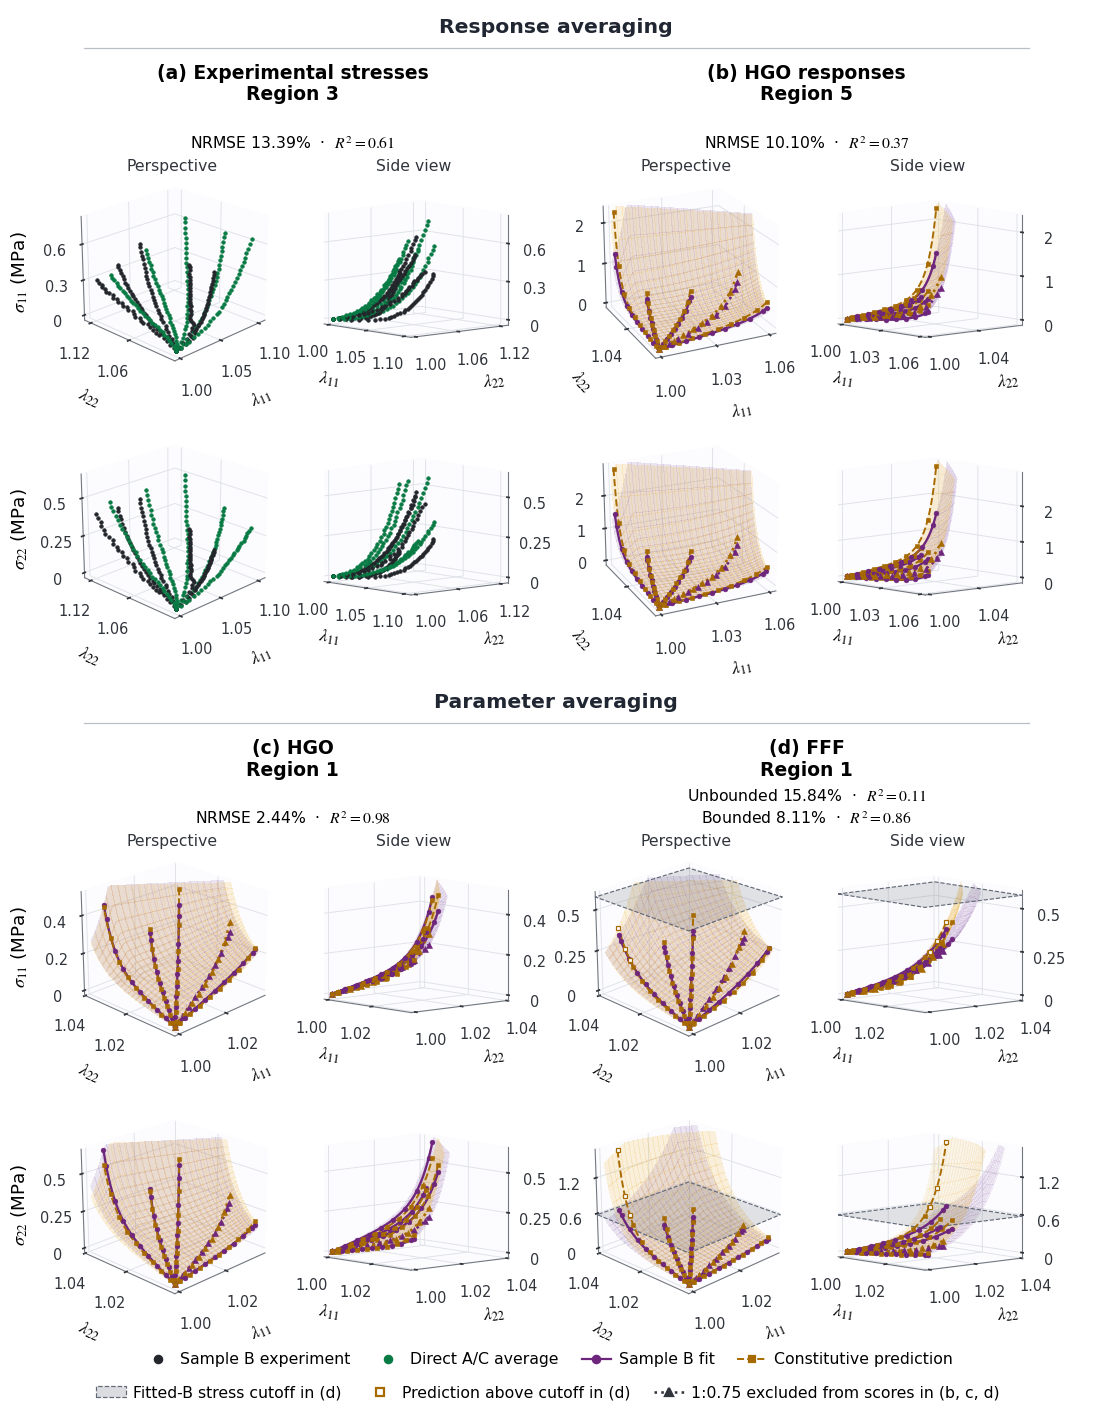

Figure 4 exports are in C:\DriveD\Research\01- PhD\Paper-Validation\Revision\Data\figure4_revised


In [19]:
def _figure4_surface(evaluate, component, max_stretch, display_max):
    """Sample the tensile surface inside the displayed stress range."""
    def stress(x, y):
        return evaluate(x, y)[component] / 1e6

    # On the tensile grid these fitted stresses increase with the stretches.
    # Interpolating the upper boundary keeps the displayed surface edge smooth.
    x_samples = np.linspace(1.0, max_stretch[0], 1001)
    y_samples = np.linspace(1.0, max_stretch[1], 1001)
    x_end = np.interp(display_max, stress(x_samples, 1.0), x_samples)
    x_grid = np.linspace(1.0, x_end, 45)
    y_ends = np.array([
        np.interp(display_max, stress(x, y_samples), y_samples) for x in x_grid
    ])
    x = np.broadcast_to(x_grid, (45, 45))
    y = 1.0 + np.linspace(0.0, 1.0, 45)[:, None] * (y_ends - 1.0)
    return x, y, stress(x, y)


def _figure4_plot_path(ax, stretch, stress, keep, component, color, *, modeled, prediction,
                       display_only=False):
    z = stress[:, component] / 1e6
    marker = "^" if display_only else ("s" if modeled and prediction else "o")
    marker_size = 2.85 if display_only else (2.15 if modeled else 1.65)
    if modeled:
        line_style = "--" if prediction else "-"
        line_width = 0.86 if prediction else 1.05
        if display_only:
            line_style, line_width = ":", 1.15
        ax.plot(stretch[:, 0], stretch[:, 1], z, color=color,
                linestyle=line_style, linewidth=line_width, zorder=5 if prediction else 4)
    stride = 36 if modeled else 10
    offset = stride // 2 if modeled and prediction else 0
    indices = np.arange(offset, len(z), stride)
    for retained in (True, False):
        shown = keep == retained
        if not shown.any():
            continue
        # Include the endpoints of each retained or excluded segment.
        edges = np.flatnonzero(np.diff(np.r_[False, shown, False]))
        marks = np.union1d(indices[shown[indices]], np.r_[edges[::2], edges[1::2] - 1])
        ax.plot(stretch[marks, 0], stretch[marks, 1], z[marks], linestyle="none", marker=marker,
                markersize=marker_size, markeredgewidth=0.55 if not retained else 0.25,
                markerfacecolor=color if retained else "white", markeredgecolor=color,
                zorder=6)


def _figure4_draw_panel(ax, panel, component, colors, *, side_view):
    letter = panel["letter"]
    xy_limits = panel["stretch_limits"]
    z_limits = panel["stress_limits"][component]
    ceiling = panel.get("ceiling")
    cutoff_color = "#616976"

    modeled = "surfaces" in panel
    if modeled:
        for evaluate, color in zip(panel["surfaces"], ("#A078B5", "#EDB946")):
            x, y, z = _figure4_surface(
                evaluate, component, panel["surface_max_stretch"], z_limits[1]
            )
            ax.plot_surface(x, y, z, rstride=2, cstride=2, color=color,
                            linewidth=0, antialiased=False, shade=False,
                            alpha=0.12 if side_view else 0.19, zorder=2)

    if ceiling is not None:
        x, y = np.meshgrid(*xy_limits)
        ax.plot_surface(x, y, np.full_like(x, ceiling / 1e6), color=cutoff_color,
                        alpha=0.18, shade=False, linewidth=0, zorder=3)
        rim = [0, 1, 3, 2, 0]
        ax.plot(x.ravel()[rim], y.ravel()[rim], np.full(5, ceiling / 1e6),
                color=cutoff_color, linestyle="--", linewidth=0.52, zorder=3.5)

    ref_color, pred_color = colors[2:] if modeled else colors[:2]
    for protocol, (xy_ref, ref, xy_pred, pred) in panel["paths"].items():
        display_only = protocol in panel["display_only_protocols"]
        all_states = np.ones(len(ref), dtype=bool)
        keep = all_states
        if ceiling is not None and not display_only:
            keep = within_stress_ceiling(pred, ceiling)
        _figure4_plot_path(ax, xy_ref, ref, all_states, component, ref_color,
                           modeled=modeled, prediction=False, display_only=display_only)
        _figure4_plot_path(ax, xy_pred, pred, keep, component, pred_color,
                           modeled=modeled, prediction=True, display_only=display_only)

    stretch_ticks = {
        "a": ((1, 1.05, 1.10), (1, 1.06, 1.12)),
        "b": ((1, 1.03, 1.06), (1, 1.04, 1.08)),
        "c": ((1, 1.02), (1, 1.02, 1.04)),
        "d": ((1, 1.02), (1, 1.02, 1.04)),
    }
    ticks = [
        [tick for tick in values if lo <= tick <= hi]
        for values, (lo, hi) in zip(stretch_ticks[letter], xy_limits)
    ]
    if not side_view:
        # The two 1.00 labels meet at the same corner in the perspective view.
        ticks[1] = [tick for tick in ticks[1] if tick != 1]
    ax.tick_params(labelsize=6.55, pad=0, length=2, colors="#30343B")
    ax.set(xlim=xy_limits[0], ylim=xy_limits[1], zlim=z_limits)
    ax.set_xlabel(r"$\lambda_{11}$", labelpad=-2, fontsize=8)
    ax.set_ylabel(r"$\lambda_{22}$", labelpad=-2, fontsize=8)
    for axis, axis_ticks in zip((ax.xaxis, ax.yaxis), ticks):
        axis.set_major_locator(FixedLocator(axis_ticks))
        axis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax.zaxis.set_major_locator(MaxNLocator(nbins=3, min_n_ticks=3))
    ax.zaxis.set_major_formatter(FormatStrFormatter("%.2g"))
    ax.zaxis.set_tick_params(pad=-1)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((0.99, 0.99, 0.995, 1))
        axis.line.set_color("#72777F")
        axis.line.set_linewidth(0.5)
        axis._axinfo["grid"].update(color="#DFE2E7", linewidth=0.42)
    ax.set_box_aspect((1, 1, 0.86), zoom=1.035)


def _figure4_panel_b_for_plot(panel):
    """Restore the excluded Region 5 path for display only."""
    stretch_paths = equivalent_stretch_paths(
        paired_data.loc[5], 5, "HGO", PREDICTORS_FOR_B, include_excluded=True,
    )
    missing_paths = set(stretch_paths) - panel["paths"].keys()
    if not missing_paths:
        return panel

    added_paths = figure4_model_paths(
        {name: stretch_paths[name] for name in missing_paths}, *panel["surfaces"],
    )
    return {
        **panel,
        "paths": {**panel["paths"], **added_paths},
        "display_only_protocols": panel["display_only_protocols"] | missing_paths,
    }


def _figure4_render(panels):
    panels = [_figure4_panel_b_for_plot(panel) if panel["letter"] == "b" else panel
              for panel in panels]
    colors = ("#23262B", "#087A43", "#6E267C", "#A66A00")
    with mpl.rc_context({"font.family": "DejaVu Sans", "mathtext.fontset": "stix",
                         "axes.unicode_minus": True}):
        # Keep the manuscript's full-width placement (about 174 mm).
        figure_height = 8.9
        fig = plt.figure(figsize=(6.85, figure_height), dpi=160, facecolor="white")
        groups = (("Response averaging", panels[:2]), ("Parameter averaging", panels[2:]))
        view_centers = ((0.157, 0.377), (0.626, 0.846))
        views = (("Perspective", False), ("Side view", True))
        axis_height = 1.261 / figure_height

        for group_index, (heading, group_panels) in enumerate(groups):
            heading_y = 1 - (0.17 + 4.22 * group_index) / figure_height
            fig.text(0.5075, heading_y, heading, ha="center", va="center", fontsize=9.2,
                     weight="bold", color="#202733")
            rule_y = heading_y - 0.13 / figure_height
            fig.add_artist(Line2D([0.0765, 0.9385], [rule_y, rule_y],
                                  transform=fig.transFigure, color="#B8BEC7", linewidth=0.55))

            stress_row_centers = [heading_y - offset / figure_height for offset in (1.53, 3.14)]
            for row_y, direction in zip(stress_row_centers, ("11", "22")):
                fig.text(0.018, row_y, rf"$\sigma_{{{direction}}}$ (MPa)", rotation=90,
                         fontsize=8.25, va="center", ha="center")

            for column_centers, panel in zip(view_centers, group_panels):
                panel_center = sum(column_centers) / 2
                fig.text(panel_center, heading_y - 0.23 / figure_height,
                         f"({panel['letter']}) {panel['title']}", ha="center", va="top",
                         fontsize=8.45, weight="bold", linespacing=1.16)
                scores = panel["scores"]
                for row, (treatment, (nrmse, r2)) in enumerate(scores.items()):
                    prefix = "NRMSE" if treatment == "Combined" else treatment
                    label = rf"{prefix} {nrmse:.2f}%  ·  $R^2={r2:.2f}$"
                    offset = 0.73 - 0.14 * (len(scores) - row - 1)
                    fig.text(panel_center, heading_y - offset / figure_height, label,
                             ha="center", va="center", fontsize=7.05)

                for center, (view_label, side_view) in zip(column_centers, views):
                    fig.text(center, heading_y - 0.87 / figure_height, view_label,
                             ha="center", va="center", fontsize=7.05, color="#30343B")
                    for component, row_y in enumerate(stress_row_centers):
                        rect = [center - 0.102, row_y - axis_height / 2, 0.204, axis_height]
                        ax = fig.add_axes(rect, projection="3d", computed_zorder=False)
                        _figure4_draw_panel(ax, panel, component, colors, side_view=side_view)
                        if side_view:
                            ax.set_proj_type("ortho")
                            ax.view_init(elev=8, azim=-42)
                        else:
                            azimuth = -115 if panel["letter"] == "b" else -135
                            ax.set_proj_type("persp")
                            ax.view_init(elev=22, azim=azimuth)

        handles = [
            Line2D([], [], marker="o", linestyle=style, color=color, markersize=3.3,
                   linewidth=1.0, label=label)
            for color, style, label in zip(
                colors[:3], ("none", "none", "-"),
                ("Sample B experiment", "Direct A/C average", "Sample B fit"),
            )
        ]
        handles.append(Line2D([], [], marker="s", linestyle="--", color=colors[3],
                              markersize=3.0, linewidth=0.86, label="Constitutive prediction"))
        fig.legend(handles=handles, loc="center", bbox_to_anchor=(0.5, 0.045), frameon=False,
                   ncol=4, fontsize=7.1, columnspacing=1.45, handletextpad=0.45, handlelength=1.9)

        cutoff_handles = [
            Patch(facecolor="#DADCE0", edgecolor="#616976", linewidth=0.55, linestyle="--",
                  label="Fitted-B stress cutoff in (d)"),
            Line2D([], [], marker="s", linestyle="none", markeredgecolor=colors[3],
                   markerfacecolor="white", markersize=3.6, label="Prediction above cutoff in (d)"),
        ]
        display_only_panels = ", ".join(
            panel["letter"] for panel in panels if panel["display_only_protocols"]
        )
        if display_only_panels:
            cutoff_handles.append(Line2D(
                [], [], marker="^", linestyle=":", linewidth=1.15, color="#30343B",
                markersize=3.6, label=f"1:0.75 excluded from scores in ({display_only_panels})",
            ))
        fig.legend(handles=cutoff_handles, loc="center", bbox_to_anchor=(0.5, 0.022), frameon=False,
                   ncol=len(cutoff_handles), fontsize=7.1, columnspacing=1.5,
                   handletextpad=0.45, handlelength=1.9)
    return fig


FIGURE4_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
figure = _figure4_render(figure4_panels)
with mpl.rc_context({"pdf.fonttype": 42}):
    figure.savefig(FIGURE4_OUTPUT_DIR / "Figure4_combined.pdf", facecolor="white")
figure.savefig(FIGURE4_OUTPUT_DIR / "Figure4_combined.png", dpi=600, facecolor="white")
plt.show()
plt.close(figure)

print(f"Figure 4 exports are in {FIGURE4_OUTPUT_DIR.resolve()}")


,Direct experimental,HGO response,FFF response,HGO unbounded,HGO bounded,FFF unbounded,FFF bounded
Region,,,,,,,
1,4.94,5.66,6.44,2.44,2.44,15.84,8.11
2,18.97,8.94,6.24,9.34,9.34,6.62,6.62
3,13.39,7.80,9.70,12.19,12.19,9.60,9.60
4,4.04,9.22,9.57,7.69,7.69,8.32,8.32
5,8.20,10.10,9.26,7.24,9.03,21.54,7.51
6,5.75,12.86,13.33,12.89,12.89,13.69,13.69


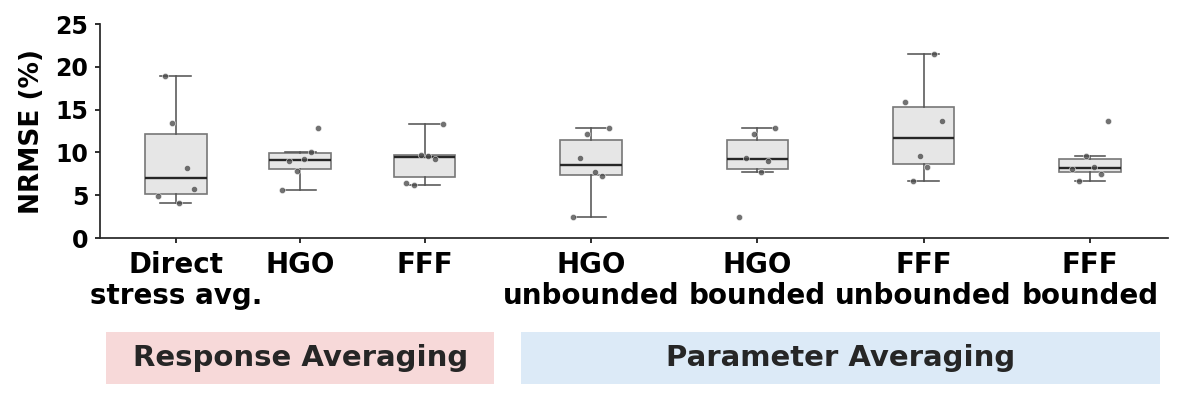

In [20]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.patches import Rectangle
from matplotlib.transforms import blended_transform_factory

# Use the six regional NRMSE values per method from Table 2.
figure5_nrmse = table2_regional_scores.xs("NRMSE (%)", axis=1, level=1)[[
    "Direct experimental", "HGO response", "FFF response", "HGO unbounded",
    "HGO bounded", "FFF unbounded", "FFF bounded",
]]
values = figure5_nrmse.to_numpy()
if list(figure5_nrmse.index) != list(range(1, 7)) or not np.isfinite(values).all():
    raise ValueError("Figure 5 requires a finite NRMSE for each method in Regions 1–6.")
display(figure5_nrmse.round(2))

positions = [1, 1.89, 2.78, 3.97, 5.16, 6.35, 7.54]
labels = [
    "Direct\nstress avg.", "HGO", "FFF",
    "HGO\nunbounded", "HGO\nbounded", "FFF\nunbounded", "FFF\nbounded",
]
region_offsets = np.linspace(-0.13, 0.13, len(figure5_nrmse))
y_top = max(25, 5 * np.ceil((values.max() + 1) / 5))
output_dir = Path("figure5_revised")
output_dir.mkdir(parents=True, exist_ok=True)

with mpl.rc_context({
    "font.family": "DejaVu Sans", "font.size": 20, "font.weight": "bold",
    "axes.labelsize": 19, "axes.labelweight": "bold",
    "xtick.labelsize": 20, "ytick.labelsize": 17, "pdf.fonttype": 42,
}):
    fig, ax = plt.subplots(figsize=(11.8, 4.0), facecolor="white")
    fig.subplots_adjust(left=0.085, right=0.99, bottom=0.405, top=0.94)
    ax.boxplot(
        values, positions=positions, widths=0.44, whis=1.5,
        patch_artist=True, showfliers=False,
        boxprops={"facecolor": "#E6E6E6", "edgecolor": "#777777", "linewidth": 1.2},
        medianprops={"color": "#262626", "linewidth": 1.7},
        whiskerprops={"color": "#555555", "linewidth": 1.15},
        capprops={"color": "#555555", "linewidth": 1.15},
    )
    for x, scores in zip(positions, values.T):
        ax.scatter(x + region_offsets, scores, s=20, color="#4A4A4A",
                   alpha=0.78, edgecolors="white", linewidths=0.45, zorder=5)

    ax.set_xticks(positions, labels, linespacing=1.12)
    ax.set_yticks(np.arange(0, y_top + 1, 5))
    ax.set(xlim=(0.46, 8.10), ylim=(0, y_top))
    ax.set_ylabel("NRMSE (%)", labelpad=8)
    ax.grid(False, which="both", axis="both")
    ax.spines[["top", "right"]].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#262626")
        ax.spines[side].set_linewidth(1.25)
    ax.tick_params(axis="x", direction="out", length=3.5, width=1.15, pad=6)
    ax.tick_params(axis="y", direction="out", length=3.5, width=1.15, pad=5)

    # Align each group band to its boxes and reserve a fixed footer for both labels.
    footer = blended_transform_factory(ax.transData, fig.transFigure)
    for group, title, fill in (
        (positions[:3], "Response Averaging", "#F7D9D9"),
        (positions[3:], "Parameter Averaging", "#DCEAF7"),
    ):
        left, right = group[0] - 0.50, group[-1] + 0.50
        ax.add_patch(Rectangle(
            (left, 0.04), right - left, 0.13, transform=footer,
            facecolor=fill, edgecolor="none", clip_on=False,
        ))
        ax.text(
            (left + right) / 2, 0.105, title, transform=footer,
            ha="center", va="center", fontsize=21, color="#262626", clip_on=False,
        )

    fig.savefig(output_dir / "Figure5_boxplot.pdf", facecolor="white")
    fig.savefig(output_dir / "Figure5_boxplot.png", dpi=600, facecolor="white")
    plt.show()
    plt.close(fig)


In [22]:
# Compare stress bounds from Samples A, B and C.
from functools import partial

import numpy as np
import pandas as pd
from IPython.display import display

bounding_sensitivity_rows = []

for (region_id, model_name), comparison in b_comparisons.items():
    reference = comparison["reference"]
    model, parameters = MODEL_DEFINITIONS[model_name]
    predicted = parameter_predictions[region_id, model_name]["Arithmetic"]

    # Preserve the original B ceiling and evaluate A/C on the same stretch paths.
    ceilings = {"B": float(reference.max())}
    for sample in ("A", "C"):
        stresses = evaluate_stresses(
            partial(model, parameters[region_id][sample]),
            comparison["stretch"],
        )
        ceilings[sample] = float(stresses.max())

    for sample in ("A", "B", "C"):
        keep = within_stress_ceiling(predicted, ceilings[sample])
        bounding_sensitivity_rows.append({
            "Region": region_id,
            "Model": model_name,
            "Bound": f"Sample {sample}",
            **score_stresses(reference[keep], predicted[keep], "Combined"),
        })

bounding_sensitivity_results = pd.DataFrame(bounding_sensitivity_rows)
bounding_sensitivity_table = make_score_table(
    bounding_sensitivity_results, ["Model", "Bound"]
)
display(bounding_sensitivity_table)


NRMSE (%) / R²       Region 1      Region 2        Region 3       Region 4  \
Model Bound                                                                  
HGO   Sample A   3.32% / 0.98  9.34% / 0.42  12.19% / -0.04  11.08% / 0.73   
      Sample B   2.44% / 0.98  9.34% / 0.42  12.19% / -0.04   7.69% / 0.81   
      Sample C   2.44% / 0.98  9.34% / 0.42    8.88% / 0.32   7.69% / 0.81   
FFF   Sample A   4.68% / 0.96  6.62% / 0.63    9.60% / 0.49  11.57% / 0.68   
      Sample B   8.11% / 0.86  6.62% / 0.63    9.60% / 0.49   8.32% / 0.73   
      Sample C  11.63% / 0.66  7.19% / 0.63   15.31% / 0.08   8.32% / 0.73   

NRMSE (%) / R²        Region 5       Region 6         Median  
Model Bound                                                   
HGO   Sample A   13.45% / 0.49  12.89% / 0.09  11.64% / 0.46  
      Sample B    9.03% / 0.59  12.89% / 0.09   9.19% / 0.51  
      Sample C    7.24% / 0.68  14.82% / 0.12   8.28% / 0.55  
FFF   Sample A  21.54% / -1.49  13.69% / 0.20  10.59% / 0.56  
      Sample B    7.51% / 0.69  13.69% / 0.20   8.21% / 0.66  
      Sample C    7.67% / 0.68  13.55% / 0.24   9.97% / 0.64